# ¿Cuánta energía cuesta romper una contraseña por fuerza bruta?

**Física A: Hardware e Información — Proyecto final**
Profesor: Andrés Flórez

**Integrantes:** Felipe Rojas Díaz · Alejandra Rodríguez · Samuel Fonseca

> **Pregunta.** ¿Cuánto tiempo y energía cuesta romper una contraseña de $N$ caracteres con una GPU que se calienta y reduce su frecuencia (*throttling*), cuánto cambia eso con la calidad de la refrigeración, y desde qué longitud la termodinámica hace imposible el ataque?

## 1. Introducción

Un ataque de fuerza bruta prueba todas las combinaciones posibles de una contraseña. Con un alfabeto de 95 caracteres imprimibles, una contraseña de $N$ caracteres tiene $95^N$ combinaciones. Una GPU moderna prueba cientos de miles de millones por segundo, pero cada intento es trabajo eléctrico que termina como **calor** en el chip. El chip se calienta, se protege bajando su frecuencia y el ataque se vuelve más lento y más caro.

En este notebook construimos ese modelo paso a paso: primero la dinámica térmica del chip, después el frenado, luego el costo del ataque y, al final, el límite fundamental que impone la termodinámica (principio de Landauer).

## 2. Modelo físico

### 2.1 Balance de energía del chip

Tratamos el chip y su disipador como **un solo cuerpo** a temperatura uniforme $T$, con capacidad térmica $C_{th} = m\,c$. Por la primera ley, la energía que entra (potencia eléctrica $P$) menos la que sale al ambiente por conducción cambia su temperatura:

$$
C_{th}\,\frac{dT}{dt} \;=\; P \;-\; \frac{T - T_{amb}}{R_{th}}
$$

- $P$: potencia eléctrica disipada por el chip (W). Toda termina como calor.
- $R_{th} = \dfrac{L}{kA}$: resistencia térmica entre el chip y el aire (K/W). Un buen disipador y buena pasta térmica dan un $R_{th}$ pequeño.
- $T_{amb}$: temperatura del ambiente.

Es exactamente la misma ecuación que la de un **circuito RC**: $C_{th}$ hace el papel del condensador, $R_{th}$ el de la resistencia y $P$ el de una fuente de corriente. Por eso aparece una constante de tiempo

$$
\tau = R_{th}\,C_{th}.
$$

### 2.2 Potencia y velocidad del ataque *(secciones 8 y 9)*

La potencia dinámica de un chip CMOS es $P \approx C\,V^2 f$ (cargar y descargar condensadores en cada ciclo de reloj), y la velocidad de intentos es proporcional a la frecuencia: $r \propto f$.

### 2.3 Frenado *(sección 9)*

Los chips tienen dos frenos: un **tope de potencia** y un **límite térmico**: si $T$ supera $T_{lím} \approx 83\ ^\circ\mathrm{C}$, el chip reduce $f$. Esa realimentación vuelve el sistema **no lineal**.

### 2.4 Refrigeración y límite de Landauer *(secciones 10 y 12)*

Sacar el calor $Q$ de un cuarto cuesta un trabajo $W = Q/\mathrm{COP}$ (cota de Carnot). Y por debajo de toda la tecnología, cada operación lógica irreversible cuesta al menos $k_B T \ln 2$.

### 2.5 Suposiciones

1. Temperatura uniforme en el chip y el disipador (un solo nodo térmico).
2. Temperatura ambiente constante.
3. $R_{th}$ constante: no cambia con la velocidad del ventilador.
4. La potencia depende de la frecuencia y del voltaje, y el voltaje baja junto con la frecuencia (sección 9.1).
5. Computación irreversible (para aplicar Landauer).

En las secciones 8 y 14 revisamos con datos cuáles de estas suposiciones se cumplen y cuáles no.

## 3. Parámetros

Todos los parámetros están en una sola celda, con unidades y origen. Los valores térmicos son **estimaciones iniciales**; los contrastamos con nuestra medición propia (sección 8).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Estilo de las gráficas (colores fijos por serie, rejilla suave)
AZUL, NARANJA, AGUA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GRIS = "#52514e"
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
    "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
})

# --- Parámetros de la GPU (referencia: RTX 4090) ---
P_MAX = 450.0    # W   potencia máxima de la tarjeta (especificación del fabricante)
T_AMB = 25.0     # °C  temperatura del cuarto
T_LIM = 83.0     # °C  límite a partir del cual el chip se frena (sección 9)

# --- Parámetros térmicos (estimaciones, a ajustar con datos propios) ---
C_TH = 600.0     # J/K disipador de ~0.67 kg de aluminio y cobre, c ≈ 900 J/(kg·K)
R_BUENO = 0.10   # K/W disipador bueno
R_MALO = 0.18    # K/W disipador malo (polvo, pasta térmica seca)

for nombre, R in [("bueno", R_BUENO), ("malo", R_MALO)]:
    tau = R * C_TH
    T_eq = T_AMB + P_MAX * R
    print(f"Disipador {nombre:5s}: tau = {tau:5.1f} s | T de equilibrio sin frenado = {T_eq:5.1f} °C")

Disipador bueno: tau =  60.0 s | T de equilibrio sin frenado =  70.0 °C
Disipador malo : tau = 108.0 s | T de equilibrio sin frenado = 106.0 °C


Con estos valores, el disipador bueno se estabiliza por debajo de $T_{lím}$ y nunca necesitaría frenar, mientras que el malo llegaría a más de 100 °C si no frenara. Esa diferencia es la que la sección 9 convierte en velocidad de ataque.

## 4. Método numérico: Euler explícito

Escribimos la ecuación como $\dfrac{dT}{dt} = F(t, T)$ con

$$
F(t,T) = \frac{1}{C_{th}}\left[P - \frac{T - T_{amb}}{R_{th}}\right].
$$

El método de Euler aproxima la derivada con una recta durante un paso $\Delta t$:

$$
T_{k+1} = T_k + \Delta t\; F(t_k, T_k), \qquad t_{k+1} = t_k + \Delta t .
$$

El error que se comete en cada paso es del orden de $\Delta t^2$, y como hay $t/\Delta t$ pasos, el error acumulado es del orden de $\Delta t$ (**método de primer orden**). Lo implementamos nosotros, sin usar integradores de librerías, y separado del modelo físico para poder reutilizarlo en las siguientes fases.

In [2]:
def euler(F, T0, dt, t_final):
    # Integra dT/dt = F(t, T) desde t = 0 hasta t_final con pasos dt.
    n = int(round(t_final / dt))
    t = np.arange(n + 1) * dt
    T = np.empty(n + 1)
    T[0] = T0
    for k in range(n):
        T[k + 1] = T[k] + dt * F(t[k], T[k])
    return t, T


def F_sin_frenado(R_th, P=P_MAX, C_th=C_TH, T_amb=T_AMB):
    # Lado derecho del balance de energía con potencia constante.
    def F(t, T):
        return (P - (T - T_amb) / R_th) / C_th
    return F


def T_analitica(t, R_th, P=P_MAX, C_th=C_TH, T_amb=T_AMB):
    # Solución exacta con T(0) = T_amb.
    tau = R_th * C_th
    return T_amb + P * R_th * (1 - np.exp(-t / tau))

## 5. Validación 1: comparación con la solución analítica

Sin frenado, la ecuación es lineal y tiene solución exacta. Con $T(0) = T_{amb}$:

$$
T(t) = T_{amb} + P\,R_{th}\left(1 - e^{-t/\tau}\right).
$$

Simulamos con Euler y $\Delta t = 1\ \mathrm{s}$ (mucho menor que $\tau$) para los dos disipadores y comparamos.

Disipador bueno: error máximo de Euler = 0.139 °C
Disipador malo: error máximo de Euler = 0.138 °C


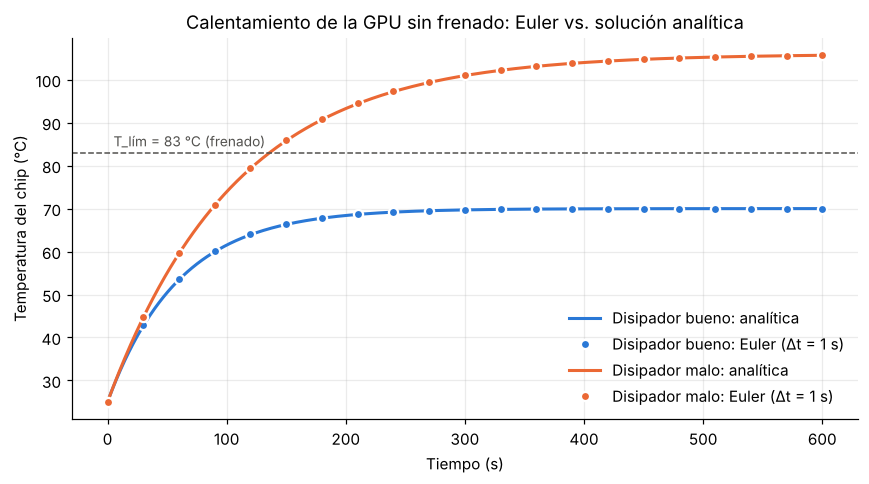

In [3]:
dt = 1.0          # s
t_final = 600.0   # s (10 minutos)
t_fino = np.linspace(0, t_final, 1000)

fig, ax = plt.subplots()
for R, color, nombre in [(R_BUENO, AZUL, "Disipador bueno"), (R_MALO, NARANJA, "Disipador malo")]:
    t, T = euler(F_sin_frenado(R), T_AMB, dt, t_final)
    ax.plot(t_fino, T_analitica(t_fino, R), color=color, lw=2, label=f"{nombre}: analítica")
    ax.plot(t[::30], T[::30], "o", color=color, ms=6, mec="white", mew=1.5,
            label=f"{nombre}: Euler (Δt = {dt:g} s)")
    err = np.max(np.abs(T - T_analitica(t, R)))
    print(f"{nombre}: error máximo de Euler = {err:.3f} °C")

ax.axhline(T_LIM, color=GRIS, ls="--", lw=1)
ax.text(5, T_LIM + 1.5, f"T_lím = {T_LIM:g} °C (frenado)", color=GRIS, fontsize=9)
ax.set_xlabel("Tiempo (s)")
ax.set_ylabel("Temperatura del chip (°C)")
ax.set_title("Calentamiento de la GPU sin frenado: Euler vs. solución analítica")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig("figuras/validacion_analitica.png", dpi=200)
plt.show()

**Interpretación.** Euler sigue la solución analítica con un error máximo menor a medio grado. Las dos curvas tienen la forma de la carga de un condensador: suben rápido al principio y se aplanan cerca de $T_{amb} + P R_{th}$. El disipador malo no solo llega más alto, también tarda más en estabilizarse porque su $\tau$ es mayor. Además, cruza la línea de 83 °C a los pocos minutos: en la realidad, en ese momento el chip empezaría a frenar, que es lo que modela la sección 9.

## 6. Validación 2: ¿cómo cambia el error con $\Delta t$?

Si Euler es de primer orden, al dividir $\Delta t$ entre 10 el error también debe dividirse aproximadamente entre 10. En una gráfica log-log eso es una recta de **pendiente 1**.

Pendiente del ajuste log-log: 1.029  (se espera ≈ 1 para Euler)


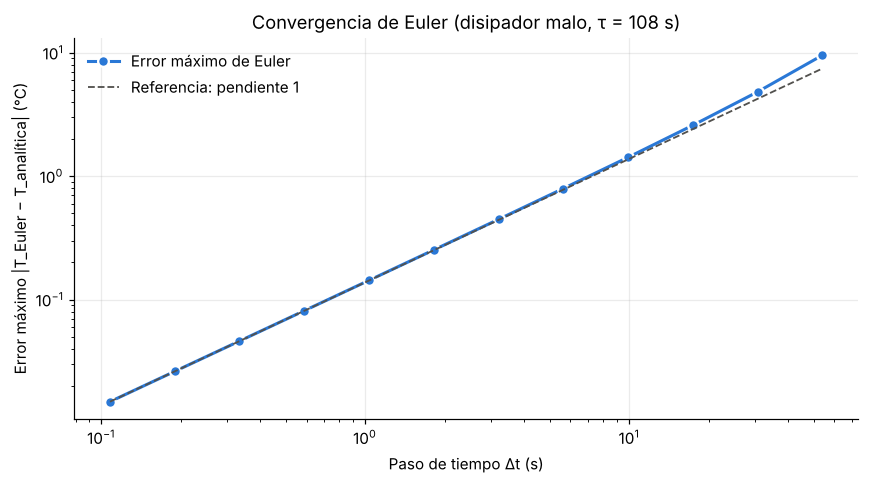

In [4]:
R = R_MALO
tau = R * C_TH
t_final = 5 * tau
pasos = tau * np.logspace(-3, np.log10(0.5), 12)   # desde tau/1000 hasta tau/2

errores = []
for h in pasos:
    t, T = euler(F_sin_frenado(R), T_AMB, h, t_final)
    errores.append(np.max(np.abs(T - T_analitica(t, R))))
errores = np.array(errores)

pendiente, _ = np.polyfit(np.log10(pasos), np.log10(errores), 1)
print(f"Pendiente del ajuste log-log: {pendiente:.3f}  (se espera ≈ 1 para Euler)")

fig, ax = plt.subplots()
ax.loglog(pasos, errores, "o-", color=AZUL, ms=7, mec="white", mew=1.5, label="Error máximo de Euler")
ax.loglog(pasos, errores[0] * (pasos / pasos[0]), "--", color=GRIS, lw=1.2, label="Referencia: pendiente 1")
ax.set_xlabel("Paso de tiempo Δt (s)")
ax.set_ylabel("Error máximo |T_Euler − T_analítica| (°C)")
ax.set_title(f"Convergencia de Euler (disipador malo, τ = {tau:.0f} s)")
ax.legend()
fig.tight_layout()
fig.savefig("figuras/convergencia_euler.png", dpi=200)
plt.show()

**Interpretación.** La pendiente sale muy cerca de 1, que confirma que nuestra implementación se comporta como un método de primer orden: el error es proporcional a $\Delta t$. En la práctica, esto nos da la regla para elegir el paso: si queremos que el error sea menor a una décima de grado, basta leer en la gráfica qué $\Delta t$ lo garantiza.

## 7. Estabilidad de Euler: ¿qué pasa si el paso es muy grande?

Llamemos $u = T - T_{eq}$ a la distancia al equilibrio. Al sustituir en Euler, cada paso multiplica esa distancia por un factor fijo:

$$
u_{k+1} = \left(1 - \frac{\Delta t}{\tau}\right) u_k .
$$

- Si $0 < \Delta t < \tau$: el factor está entre 0 y 1, y la solución se acerca al equilibrio sin oscilar (correcto).
- Si $\tau < \Delta t < 2\tau$: el factor es negativo, y la solución **oscila** alrededor del equilibrio aunque la física real no oscila.
- Si $\Delta t > 2\tau$: el factor tiene valor absoluto mayor que 1, y la solución **diverge**.

Este es exactamente el tipo de pregunta de la sustentación: "¿qué pasa si duplican el paso de tiempo?".

Δt = 0.5τ -> factor por paso 1 - Δt/τ = +0.50
Δt = 1.5τ -> factor por paso 1 - Δt/τ = -0.50
Δt = 2.2τ -> factor por paso 1 - Δt/τ = -1.20


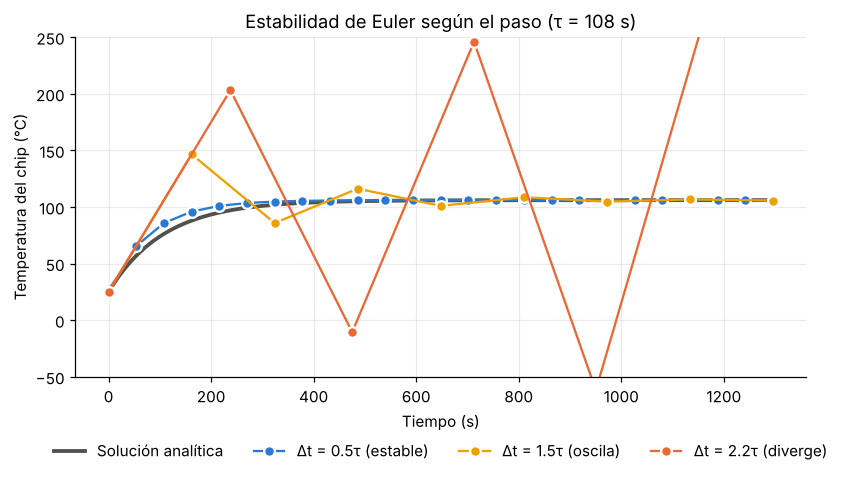

In [5]:
R = R_MALO
tau = R * C_TH
t_final = 12 * tau
t_fino = np.linspace(0, t_final, 1000)

fig, ax = plt.subplots()
ax.plot(t_fino, T_analitica(t_fino, R), color=GRIS, lw=2.5, label="Solución analítica")
casos = [(0.5, AZUL, "estable"), (1.5, AMARILLO, "oscila"), (2.2, NARANJA, "diverge")]
for factor, color, nombre in casos:
    t, T = euler(F_sin_frenado(R), T_AMB, factor * tau, t_final)
    ax.plot(t, T, "o-", color=color, ms=7, lw=1.5, mec="white", mew=1.5,
            label=f"Δt = {factor:g}τ ({nombre})")
    print(f"Δt = {factor:g}τ -> factor por paso 1 - Δt/τ = {1 - factor:+.2f}")

ax.set_ylim(-50, 250)
ax.set_xlabel("Tiempo (s)")
ax.set_ylabel("Temperatura del chip (°C)")
ax.set_title(f"Estabilidad de Euler según el paso (τ = {tau:.0f} s)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4)
fig.tight_layout()
fig.savefig("figuras/estabilidad_euler.png", dpi=200)
plt.show()

**Interpretación.** Con $\Delta t = 0.5\tau$ la simulación es tosca pero correcta. Con $\Delta t = 1.5\tau$ aparecen oscilaciones que no son físicas: el chip no "rebota" de temperatura en la realidad, es un artefacto del método. Con $\Delta t = 2.2\tau$ la temperatura crece sin límite. Conclusión práctica: en todas las simulaciones usaremos $\Delta t \ll \tau$. Esto será todavía más importante con el frenado, porque la regla de control también puede producir oscilaciones numéricas.

---
## 8. Medición propia

Para tener datos reales pusimos a trabajar los procesadores de nuestros portátiles con `medicion/benchmark.py`: todos los núcleos calculan hashes SHA-256 durante 15 minutos y luego el equipo queda 5 minutos en reposo. El script registra los hashes por segundo; al mismo tiempo, el programa **HWiNFO64** registra la temperatura del procesador, su potencia eléctrica y su frecuencia de reloj efectiva. Los dos archivos se unen por la hora del computador.

**Equipo 1:** ASUS TUF Gaming F15 (Intel Core de 4 núcleos y 8 hilos), conectado a la corriente. El portátil tiene tres modos (**Silencio**, **Rendimiento** y **Turbo**) que cambian el tope de potencia y la curva del ventilador. Primero analizamos en detalle el modo Silencio y luego comparamos los tres (sección 8.5).

### 8.1 Lectura de los datos

In [6]:
import csv
from datetime import datetime
from scipy.optimize import curve_fit

DATOS = "medicion/datos/"

def leer_benchmark(ruta):
    # CSV de benchmark.py: hora, t_s, fase, hashes_total, hashes_por_s, ...
    with open(ruta, encoding="utf-8") as f:
        filas = list(csv.DictReader(f))
    return {
        "inicio": datetime.fromisoformat(filas[0]["hora"]),
        "t": np.array([float(r["t_s"]) for r in filas]),
        "tasa": np.array([float(r["hashes_por_s"]) for r in filas]),
        "carga": np.array([r["fase"] == "carga" for r in filas]),
    }

def _hora_hwinfo(fecha, hora):
    # HWiNFO escribe la fecha como 15.11.2026 y la hora como 18:2:44.196
    d, m, a = fecha.split(".")
    h, mi, s = hora.split(":")
    seg, _, ms = s.partition(".")
    return datetime(int(a), int(m), int(d), int(h), int(mi), int(seg), int(ms.ljust(6, "0")[:6]))

# Nombres de columna posibles (HWiNFO en español o inglés, Intel o AMD)
COLUMNAS_HWINFO = {
    "T": ["CPU Entera [°C]", "CPU Package [°C]", "CPU (Tctl/Tdie) [°C]"],
    "P": ["Potencia total de CPU [W]", "CPU Package Power [W]"],
    "f": ["Relojes efectivos núcleo (avg) [MHz]", "Core Effective Clocks (avg) [MHz]"],
    "V": ["Core VIDs (avg) [V]", "VID núcleo (avg) [V]", "CPU Core Voltage (SVI2 TFN) [V]"],
    "ventilador": ["CPU [RPM]"],
    "freno_termico": ["Desaceleración térmica del núcleo (avg) [Yes/No]", "Core Thermal Throttling (avg) [Yes/No]"],
}

def _numero(texto):
    # HWiNFO escribe números o Sí/No
    if texto in ("Sí", "Si", "Yes"): return 1.0
    if texto == "No": return 0.0
    return float(texto)

def leer_hwinfo(ruta, inicio):
    # Devuelve el tiempo en segundos medido desde el inicio del benchmark
    with open(ruta, encoding="utf-8-sig", errors="replace") as f:
        filas = list(csv.reader(f))
    encabezado = filas[0]
    datos = [r for r in filas[1:] if r and r[0][:1].isdigit()]   # descarta filas de resumen
    salida = {"t": np.array([(_hora_hwinfo(r[0], r[1]) - inicio).total_seconds() for r in datos])}
    for clave, nombres in COLUMNAS_HWINFO.items():
        i = next((encabezado.index(n) for n in nombres if n in encabezado), None)
        salida[clave] = np.array([_numero(r[i]) for r in datos]) if i is not None else None
    return salida

bm = leer_benchmark(DATOS + "felipe_silencio_benchmark.csv")
hw = leer_hwinfo(DATOS + "felipe_silencio_hwinfo.csv", bm["inicio"])
t_fin_carga = bm["t"][bm["carga"]].max()
print(f"Benchmark: {len(bm['t'])} registros | HWiNFO: {len(hw['t'])} registros")
print(f"Fin de la carga: t = {t_fin_carga:.0f} s")

Benchmark: 1181 registros | HWiNFO: 604 registros
Fin de la carga: t = 901 s


### 8.2 Lo que pasó durante la medición

Graficamos temperatura, potencia y velocidad en tres paneles con el mismo eje de tiempo. La zona gris es el enfriamiento.

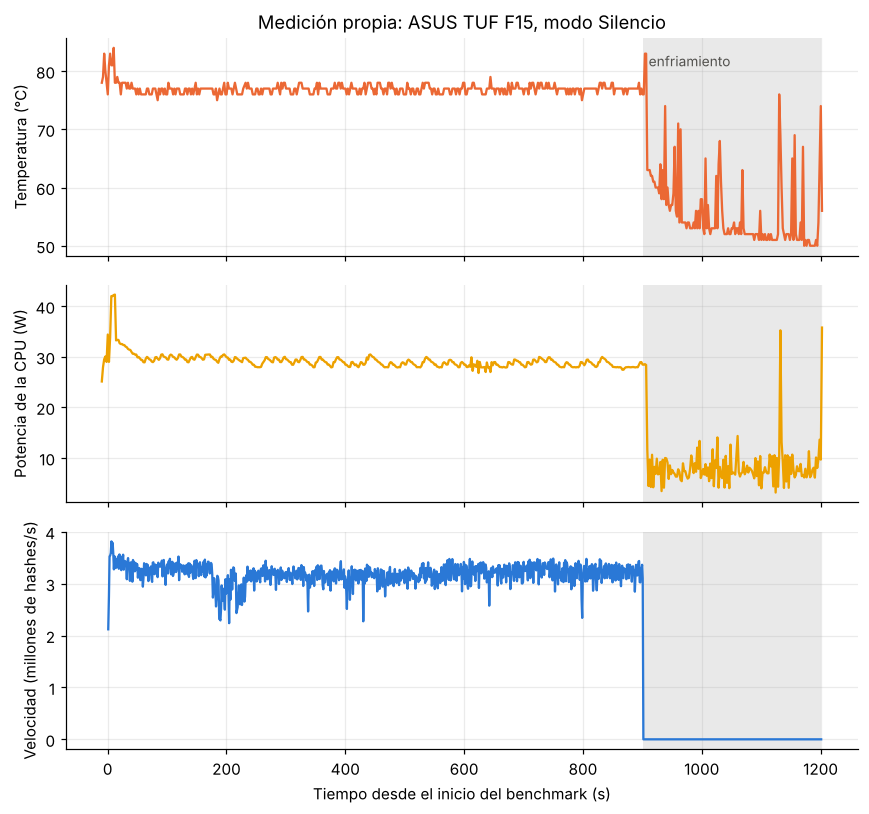

Primeros 10 s de carga: P máx = 42 W
Carga estable: T = 76.9 °C | P = 28.9 W | f efectiva = 2932 MHz
Reposo final:  T = 51.0 °C | P = 7.7 W


In [7]:
fig, ejes = plt.subplots(3, 1, figsize=(8, 7.5), sharex=True)
paneles = [
    (hw["t"], hw["T"], "Temperatura (°C)", NARANJA),
    (hw["t"], hw["P"], "Potencia de la CPU (W)", AMARILLO),
    (bm["t"][1:], bm["tasa"][1:] / 1e6, "Velocidad (millones de hashes/s)", AZUL),
]
for ax, (t, y, etiqueta, color) in zip(ejes, paneles):
    ax.axvspan(t_fin_carga, bm["t"].max(), color=GRIS, alpha=0.12, lw=0)
    ax.plot(t, y, color=color, lw=1.5)
    ax.set_ylabel(etiqueta)
ejes[0].text(t_fin_carga + 10, ejes[0].get_ylim()[1] * 0.97, "enfriamiento", color=GRIS, va="top", fontsize=9)
ejes[-1].set_xlabel("Tiempo desde el inicio del benchmark (s)")
ejes[0].set_title("Medición propia: ASUS TUF F15, modo Silencio")
fig.tight_layout()
fig.savefig("figuras/medicion_silencio.png", dpi=200)
plt.show()

carga = (hw["t"] > 60) & (hw["t"] < t_fin_carga)
reposo = hw["t"] > bm["t"].max() - 100
print("Primeros 10 s de carga: P máx = %.0f W" % hw["P"][(hw["t"] > 0) & (hw["t"] < 12)].max())
print("Carga estable: T = %.1f °C | P = %.1f W | f efectiva = %.0f MHz"
      % (hw["T"][carga].mean(), hw["P"][carga].mean(), hw["f"][carga].mean()))
print("Reposo final:  T = %.1f °C | P = %.1f W" % (np.median(hw["T"][reposo]), np.median(hw["P"][reposo])))

**Interpretación.** Se ven tres cosas importantes:

1. **El frenado en este modo es por potencia, no por temperatura.** Al arrancar, el procesador sube a unos 42 W durante unos 10 s (límite de corto plazo, *PL2*) y luego baja a unos 29 W (límite sostenido, *PL1*). HWiNFO marca "límite de potencia excedido: Sí" y "desaceleración térmica: No". El modo Silencio fija un tope de potencia bajo para que el ventilador no tenga que girar rápido. Al bajar la potencia, baja la frecuencia y con ella la velocidad de hashes (unos 5 % menos que en el primer minuto).
2. **La temperatura se estabiliza en unos 77 °C**, por debajo del límite térmico del chip, que es justo lo que predice el balance de energía: con potencia constante, $T$ tiende a $T_{amb} + P R_{th}$.
3. **El equipo ya estaba caliente al empezar** (unos 76 °C, con otros programas usando la CPU), así que esta medición no muestra la curva de calentamiento. Por eso usamos la de **enfriamiento**.

### 8.3 Ajuste de la curva de enfriamiento: medir $\tau$

Al quitar la carga, la potencia cae casi a cero y el balance de energía predice un decaimiento exponencial (ley de enfriamiento de Newton):

$$
T(t) = T_\infty + A\,e^{-t/\tau}.
$$

Empezamos el ajuste en la primera muestra en que la potencia ya cayó (menos de 15 W) y ajustamos $T_\infty$, $A$ y $\tau$ por mínimos cuadrados. Antes, quitamos los picos breves que producen otros programas del sistema operativo tomando el mínimo de cada 3 muestras vecinas.

tau medido = 44 ± 4 s | T_inf = 51.4 °C


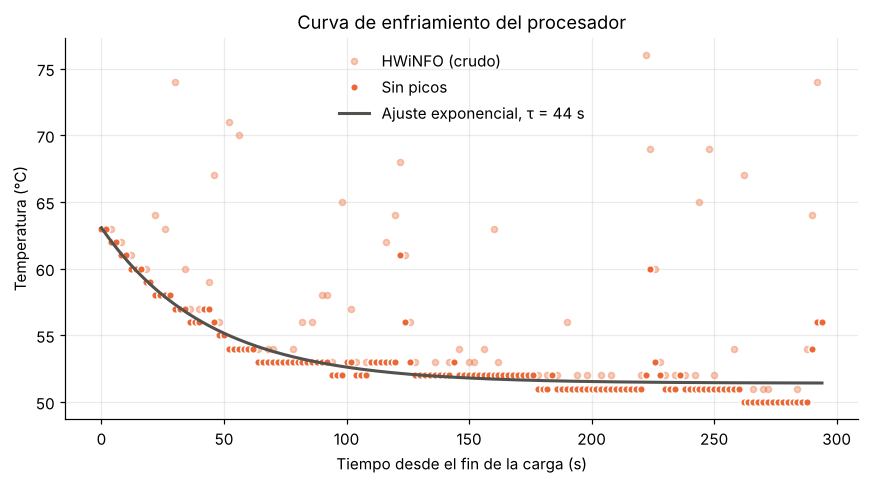

R_th efectiva = (76.9 − 51.0) °C / (28.9 − 7.7) W = 1.22 K/W
C_th efectiva = tau / R_th = 36 J/K


In [8]:
i0 = np.argmax((hw["t"] > t_fin_carga) & (hw["P"] < 15))   # primera muestra ya sin carga
m = np.arange(len(hw["t"])) >= i0
t_enf = hw["t"][m] - hw["t"][m][0]
T_enf = hw["T"][m]
T_suave = np.array([T_enf[max(0, i - 1):i + 2].min() for i in range(len(T_enf))])

def enfriamiento(t, T_inf, A, tau):
    return T_inf + A * np.exp(-t / tau)

(T_inf, A, tau_med), cov = curve_fit(enfriamiento, t_enf, T_suave, p0=[50, 10, 30])
err_tau = np.sqrt(cov[2, 2])
print(f"tau medido = {tau_med:.0f} ± {err_tau:.0f} s | T_inf = {T_inf:.1f} °C")

fig, ax = plt.subplots()
ax.plot(t_enf, T_enf, "o", color=NARANJA, ms=4, alpha=0.35, label="HWiNFO (crudo)")
ax.plot(t_enf, T_suave, "o", color=NARANJA, ms=5, mec="white", mew=1, label="Sin picos")
t_fino = np.linspace(0, t_enf.max(), 400)
ax.plot(t_fino, enfriamiento(t_fino, T_inf, A, tau_med), color=GRIS, lw=2,
        label=f"Ajuste exponencial, τ = {tau_med:.0f} s")
ax.set_xlabel("Tiempo desde el fin de la carga (s)")
ax.set_ylabel("Temperatura (°C)")
ax.set_title("Curva de enfriamiento del procesador")
ax.legend()
fig.tight_layout()
fig.savefig("figuras/enfriamiento_silencio.png", dpi=200)
plt.show()

# Resistencia térmica efectiva a partir de los dos estados estables (carga y reposo)
T_c, P_c = hw["T"][carga].mean(), hw["P"][carga].mean()
T_r, P_r = np.median(hw["T"][reposo]), np.median(hw["P"][reposo])
R_med = (T_c - T_r) / (P_c - P_r)
C_med = tau_med / R_med
print(f"R_th efectiva = ({T_c:.1f} − {T_r:.1f}) °C / ({P_c:.1f} − {P_r:.1f}) W = {R_med:.2f} K/W")
print(f"C_th efectiva = tau / R_th = {C_med:.0f} J/K")

**Interpretación.** Apenas se quita la carga, la temperatura cae unos 14 °C en menos de 2 s (antes de que empiece el ajuste): es el propio chip de silicio, que tiene muy poca masa y se enfría casi al instante. Después viene la parte lenta, que es el disipador y los tubos de calor, y que sí sigue muy bien una exponencial con $\tau \approx 44 \pm 4$ s.

Con la resistencia térmica efectiva (unos 1.2 K/W) obtenemos $C_{th} = \tau/R_{th} \approx 36$ J/K, que equivale a unos 90 g de cobre ($c = 385$ J/(kg·K)): razonable para el sistema de refrigeración de un portátil, y mucho menor que el de una tarjeta de escritorio como la RTX 4090.

Esta medición también muestra **límites de nuestro modelo de un solo nodo**: el chip y el disipador se comportan como dos cuerpos con tiempos distintos, y el ventilador cambia de velocidad en el reposo (de 3400 a 2400 rpm), lo que cambia $R_{th}$. Lo discutimos en la sección de limitaciones.

### 8.4 Energía por intento en nuestro portátil

In [9]:
r_c = bm["tasa"][bm["carga"] & (bm["t"] > 60)].mean()
E_hash = P_c / r_c
combinaciones = 95**8
t_8 = combinaciones / r_c
E_8 = combinaciones * E_hash
print(f"Velocidad estable: {r_c:.2e} hashes/s | Potencia: {P_c:.1f} W")
print(f"Energía por hash: {E_hash * 1e6:.1f} µJ  (RTX 4090 con NTLM: {P_MAX / 3e11 * 1e9:.1f} nJ)")
print(f"Contraseña de 8 caracteres en este portátil: {t_8 / 3.156e7:.0f} años y {E_8 / 3.6e6:,.0f} kWh (solo la CPU)")

Velocidad estable: 3.18e+06 hashes/s | Potencia: 28.9 W
Energía por hash: 9.1 µJ  (RTX 4090 con NTLM: 1.5 nJ)
Contraseña de 8 caracteres en este portátil: 66 años y 16,732 kWh (solo la CPU)


**Interpretación.** El portátil gasta unos 9 µJ por hash. Romper una contraseña de 8 caracteres le tomaría unos 66 años y unos 17 000 kWh solo en la CPU, lo que consume un hogar colombiano promedio en casi una década. Una GPU como la RTX 4090 hace el mismo trabajo en horas: es unas $10^5$ veces más rápida y, además, gasta unas 6000 veces menos energía por intento (1.5 nJ). Por eso los ataques reales se hacen con GPU. La comparación es aproximada: el hash de la GPU (NTLM) es más simple que SHA-256 y nuestro código está en Python.

### 8.5 Comparación de los tres modos

Repetimos la misma medición (15 min de carga y 5 min de reposo) en los modos Rendimiento y Turbo. Para cada modo calculamos los valores promedio en la carga estable (de $t = 60$ s al final de la carga).

In [10]:
MODOS = ["silencio", "rendimiento", "turbo"]
COLOR_MODO = {"silencio": AZUL, "rendimiento": AGUA, "turbo": NARANJA}

def resumen(quien, modo):
    # Promedios de la carga estable, R_th efectiva y tau del enfriamiento para una medición
    b = leer_benchmark(DATOS + f"{quien}_{modo}_benchmark.csv")
    h = leer_hwinfo(DATOS + f"{quien}_{modo}_hwinfo.csv", b["inicio"])
    fin = b["t"][b["carga"]].max()
    c = (h["t"] > 60) & (h["t"] < fin)
    rep = h["t"] > b["t"].max() - 100
    r = b["tasa"][b["carga"] & (b["t"] > 60)].mean()
    P, T = h["P"][c].mean(), h["T"][c].mean()
    # curva de enfriamiento, igual que en 8.3
    i0 = np.argmax((h["t"] > fin) & (h["P"] < 15))
    t_e, T_e = h["t"][i0:] - h["t"][i0], h["T"][i0:]
    T_e = np.array([T_e[max(0, i - 1):i + 2].min() for i in range(len(T_e))])
    (_, _, tau), cov = curve_fit(enfriamiento, t_e, T_e, p0=[50, 10, 30])
    return {
        "r": r, "P": P, "T": T, "f": h["f"][c].mean(), "V": h["V"][c].mean(),
        "ventilador": h["ventilador"][c].mean(), "E_hash": P / r,
        "R_th": (T - np.median(h["T"][rep])) / (P - np.median(h["P"][rep])),
        "tau": tau, "err_tau": np.sqrt(cov[2, 2]),
        "muestras": (h["P"][c], h["V"][c], h["f"][c]),
        "hw": h,
    }


resultados = {modo: resumen("felipe", modo) for modo in MODOS}

print(f"{'Modo':12s}{'hash/s':>10s}{'P (W)':>8s}{'f (MHz)':>9s}{'V (V)':>8s}{'T (°C)':>8s}{'vent. (rpm)':>12s}{'µJ/hash':>9s}{'R_th (K/W)':>11s}")
for modo, x in resultados.items():
    print(f"{modo:12s}{x['r']:10.2e}{x['P']:8.1f}{x['f']:9.0f}{x['V']:8.3f}{x['T']:8.1f}"
          f"{x['ventilador']:12.0f}{x['E_hash'] * 1e6:9.2f}{x['R_th']:11.2f}")

base = resultados["silencio"]
for modo in ["rendimiento", "turbo"]:
    x = resultados[modo]
    print(f"{modo} vs. silencio: velocidad {100 * (x['r'] / base['r'] - 1):+.0f} % | "
          f"potencia {100 * (x['P'] / base['P'] - 1):+.0f} % | energía por hash {100 * (x['E_hash'] / base['E_hash'] - 1):+.0f} %")

Modo            hash/s   P (W)  f (MHz)   V (V)  T (°C) vent. (rpm)  µJ/hash R_th (K/W)
silencio      3.18e+06    28.9     2932   0.904    76.9        3400     9.08       1.22
rendimiento   3.57e+06    37.1     3295   0.972    77.4        4901    10.39       0.99
turbo         3.89e+06    45.9     3570   1.032    81.3        5650    11.82       0.92
rendimiento vs. silencio: velocidad +12 % | potencia +28 % | energía por hash +14 %
turbo vs. silencio: velocidad +22 % | potencia +59 % | energía por hash +30 %


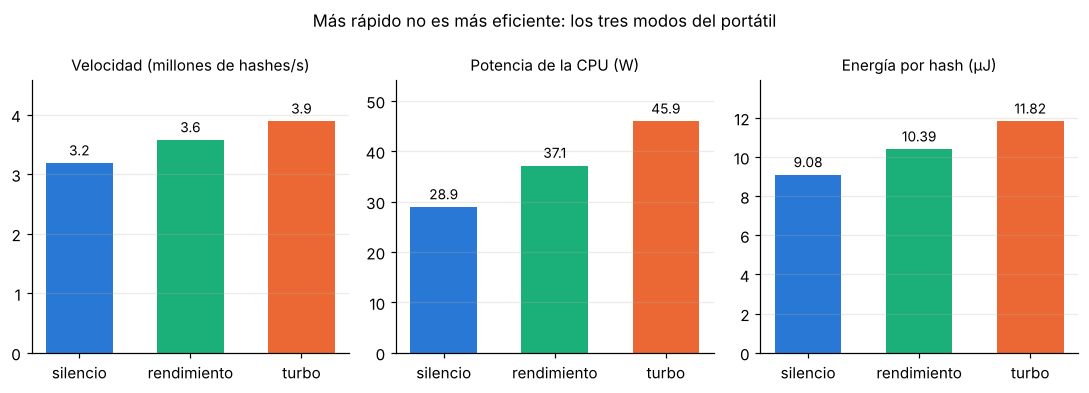

In [11]:
fig, ejes = plt.subplots(1, 3, figsize=(10, 3.6))
datos_barras = [
    ("r", 1e-6, "Velocidad (millones de hashes/s)"),
    ("P", 1, "Potencia de la CPU (W)"),
    ("E_hash", 1e6, "Energía por hash (µJ)"),
]
for ax, (clave, escala, titulo) in zip(ejes, datos_barras):
    valores = [resultados[m][clave] * escala for m in MODOS]
    barras = ax.bar(MODOS, valores, color=[COLOR_MODO[m] for m in MODOS], width=0.6)
    ax.bar_label(barras, fmt="%.1f" if clave != "E_hash" else "%.2f", padding=3, fontsize=9)
    ax.set_title(titulo, fontsize=10)
    ax.set_ylim(0, max(valores) * 1.18)
    ax.grid(axis="x", visible=False)
fig.suptitle("Más rápido no es más eficiente: los tres modos del portátil", fontsize=11)
fig.tight_layout()
fig.savefig("figuras/comparacion_modos.png", dpi=200)
plt.show()

**Interpretación.** Turbo prueba un 22 % más de contraseñas por segundo que Silencio, pero gasta un 59 % más de potencia, así que **cada intento cuesta un 30 % más de energía**. Era la predicción que hicimos a partir de $P \approx C V^2 f$: para subir la frecuencia el chip también tiene que subir el voltaje, y la potencia crece más rápido que la velocidad.

En los tres modos HWiNFO marca "límite de potencia excedido: Sí" y "desaceleración térmica: No": en este portátil el freno siempre es el **tope de potencia** que fija cada modo, y la temperatura (77 a 81 °C) es la consecuencia. El ventilador también cambia con el modo (de 3400 a 5650 rpm): más aire es más convección y por eso $R_{th}$ efectiva baja de 1.2 a 0.9 K/W.

### 8.6 Prueba directa del modelo de potencia: $P = C\,V^2 f$

HWiNFO también registra el voltaje de los núcleos. Si el modelo es correcto, al graficar $P$ contra $V^2 f$ todos los puntos, de los tres modos, deben caer sobre **una sola recta que pasa por el origen**, cuya pendiente es la capacitancia efectiva $C$ que el chip carga y descarga en cada ciclo.

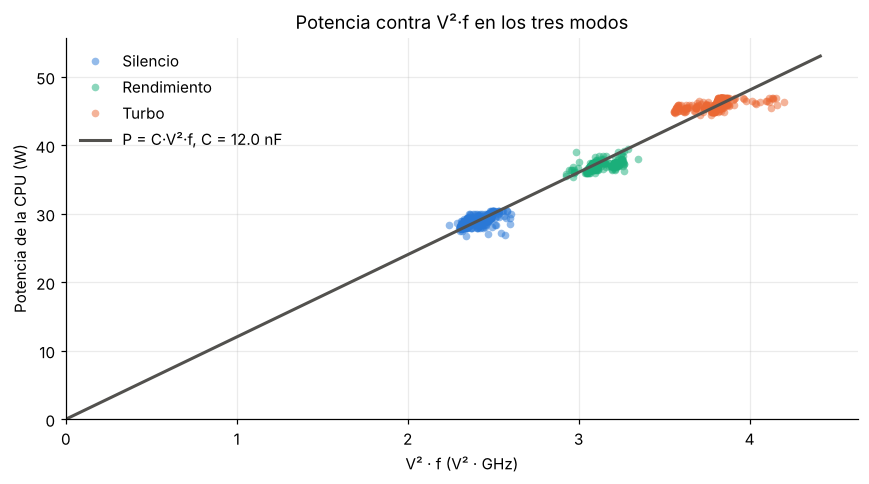

Capacitancia efectiva: C = 12.0 nF | R² = 0.986
Con intercepto libre: C = 12.0 nF, b = 0.10 W
  silencio     P/(V²f) = 12.06 nF
  rendimiento  P/(V²f) = 11.92 nF
  turbo        P/(V²f) = 12.09 nF


In [12]:
fig, ax = plt.subplots()
todos_x, todos_P = [], []
for modo in MODOS:
    P_m, V_m, f_m = resultados[modo]["muestras"]
    x = V_m**2 * f_m * 1e6          # V² · Hz
    ax.plot(x / 1e9, P_m, "o", color=COLOR_MODO[modo], ms=5, alpha=0.5, mec="none", label=modo.capitalize())
    todos_x.append(x); todos_P.append(P_m)
todos_x, todos_P = np.concatenate(todos_x), np.concatenate(todos_P)

C_ef = np.sum(todos_x * todos_P) / np.sum(todos_x**2)     # mínimos cuadrados, recta por el origen
residuo = todos_P - C_ef * todos_x
R2 = 1 - np.sum(residuo**2) / np.sum((todos_P - todos_P.mean())**2)
x_linea = np.linspace(0, todos_x.max() * 1.05, 50)
ax.plot(x_linea / 1e9, C_ef * x_linea, color=GRIS, lw=2, label=f"P = C·V²·f, C = {C_ef * 1e9:.1f} nF")
ax.set_xlim(left=0); ax.set_ylim(bottom=0)
ax.set_xlabel("V² · f (V² · GHz)")
ax.set_ylabel("Potencia de la CPU (W)")
ax.set_title("Potencia contra V²·f en los tres modos")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig("figuras/potencia_cv2f.png", dpi=200)
plt.show()

print(f"Capacitancia efectiva: C = {C_ef * 1e9:.1f} nF | R² = {R2:.3f}")

# Prueba más exigente: dejar libre el intercepto, P = C·V²f + b. Si el modelo es bueno, b ≈ 0.
(C_libre, b_libre), *_ = np.linalg.lstsq(np.vstack([todos_x, np.ones_like(todos_x)]).T, todos_P, rcond=None)
print(f"Con intercepto libre: C = {C_libre * 1e9:.1f} nF, b = {b_libre:.2f} W")
for modo in MODOS:
    P_m, V_m, f_m = resultados[modo]["muestras"]
    print(f"  {modo:12s} P/(V²f) = {np.mean(P_m / (V_m**2 * f_m * 1e6)) * 1e9:.2f} nF")

**Interpretación.** Entre los modos la potencia cambia un 59 %, pero el cociente $P/(V^2 f)$ es prácticamente el mismo en los tres (unos 12 nF). Si dejamos libre el intercepto, el ajuste da $b \approx 0.1$ W, o sea que la recta sí pasa por el origen sin que la obliguemos. Nuestros datos son **consistentes** con $P = C V^2 f$. La $C$ que obtenemos no es la de un solo transistor: es la capacitancia total que el chip conmuta en cada ciclo de reloj.

Hay dos cautelas para no decir más de lo que medimos. Primero, la potencia que reporta HWiNFO no viene de un vatímetro: es la que el propio procesador estima con sus contadores internos (RAPL), y el voltaje es el que el chip *solicita* (VID), no uno medido con un multímetro. Una parte de la relación podría venir del modelo interno del chip. Segundo, los tres modos cubren un rango estrecho ($V^2 f$ entre 2.2 y 4.2 V²·GHz), lejos del origen. Una prueba más fuerte sería medir la potencia del portátil desde el enchufe con un vatímetro.

**Sobre $\tau$:** solo el modo Silencio da una curva de enfriamiento limpia. En Rendimiento y Turbo el ventilador baja de velocidad en escalones durante el reposo y el sistema operativo tuvo actividad de fondo (picos de hasta 46 W), así que $R_{th}$ cambia durante el enfriamiento y una sola exponencial no describe bien los datos. Por eso usamos $\tau \approx 44$ s del modo Silencio como valor medido.

### 8.7 Segundo equipo: el portátil de Alejandra

**Equipo 2:** ASUS VivoBook 15 (Intel de 4 núcleos y 8 hilos), un portátil delgado sin refrigeración "gamer", medido en los modos **Silencio** y **Rendimiento**. Esta vez HWiNFO registró una muestra por segundo, y en el modo Rendimiento el equipo empezó frío, así que también tenemos la curva de calentamiento.

In [13]:
resultados_ale = {modo: resumen("alejandra", modo) for modo in ["silencio", "rendimiento"]}
todas = [("Felipe", m, resultados[m]) for m in MODOS] + [("Alejandra", m, x) for m, x in resultados_ale.items()]

print(f"{'Equipo':10s}{'Modo':12s}{'hash/s':>9s}{'P (W)':>7s}{'V (V)':>7s}{'T (°C)':>7s}{'vent.':>7s}"
      f"{'µJ/hash':>9s}{'R_th':>6s}{'τ enfr. (s)':>16s}{'P/(V²f) (nF)':>14s}")
for quien, modo, x in todas:
    P_m, V_m, f_m = x["muestras"]
    C_m = np.mean(P_m / (V_m**2 * f_m * 1e6)) * 1e9
    print(f"{quien:10s}{modo:12s}{x['r']:9.2e}{x['P']:7.1f}{x['V']:7.3f}{x['T']:7.1f}{x['ventilador']:7.0f}"
          f"{x['E_hash'] * 1e6:9.2f}{x['R_th']:6.2f}{x['tau']:8.0f} ± {x['err_tau']:<3.0f}"
          f"{'*' if x['err_tau'] > 0.15 * x['tau'] else ' ':3s}{C_m:12.2f}")
print("\n* τ poco confiable: incertidumbre mayor al 15 % (ventilador cambiando y actividad de fondo durante el enfriamiento)")

Equipo    Modo           hash/s  P (W)  V (V) T (°C)  vent.  µJ/hash  R_th     τ enfr. (s)  P/(V²f) (nF)
Felipe    silencio     3.18e+06   28.9  0.904   76.9   3400     9.08  1.22      44 ± 4            12.06
Felipe    rendimiento  3.57e+06   37.1  0.972   77.4   4901    10.39  0.99      27 ± 25 *         11.92
Felipe    turbo        3.89e+06   45.9  1.032   81.3   5650    11.82  0.92      77 ± 12 *         12.09
Alejandra silencio     3.60e+06   21.1  0.855   80.6   4479     5.87  2.17      40 ± 1             9.60
Alejandra rendimiento  3.55e+06   21.0  0.856   77.4   5388     5.91  2.01      33 ± 1             9.51

* τ poco confiable: incertidumbre mayor al 15 % (ventilador cambiando y actividad de fondo durante el enfriamiento)


**Interpretación.**

- **Mismo trabajo, menos energía.** El portátil de Alejandra calcula unos 3.6 millones de hashes por segundo, casi lo mismo que el de Felipe, pero con solo 21 W: **unos 5.9 µJ por hash, un 35 % menos** que el modo más eficiente de Felipe. Su chip trabaja a menor voltaje (0.86 V contra 0.90 a 1.03 V) y conmuta menos capacitancia por ciclo.
- **La ley $P = C V^2 f$ se cumple también en otro chip.** En sus dos modos el cociente $P/(V^2 f)$ vuelve a ser constante, unos 9.5 nF: es la $C$ propia de su procesador, distinta de los 12 nF del de Felipe.
- **Disipador más pequeño, $R_{th}$ más grande.** Su resistencia térmica efectiva es de unos 2 K/W, casi el doble que la del portátil gamer. Por eso con apenas 21 W ya llega a unos 80 °C.
- **Un experimento controlado.** En este portátil los dos modos dan la misma potencia y la misma frecuencia (21 W y 3.0 GHz); lo único que cambia es el ventilador (unos 4500 contra 5400 rpm). Con la misma $P$, más aire significa menor $R_{th}$ y por eso la temperatura baja de 80.6 a 77.4 °C, tal como predice $T = T_{amb} + P R_{th}$. Los valores de $\tau$ de enfriamiento, ahora con datos cada segundo, salen con incertidumbre de ±1 s: 40 s en Silencio y 33 s en Rendimiento (con más ventilador, $R_{th}$ y $\tau = R_{th}C_{th}$ bajan).

Silencio: freno térmico activo entre t = 43 y 93 s, T máx = 92 °C
Rendimiento: τ de calentamiento = 9.5 ± 0.4 s | τ de enfriamiento = 33 s


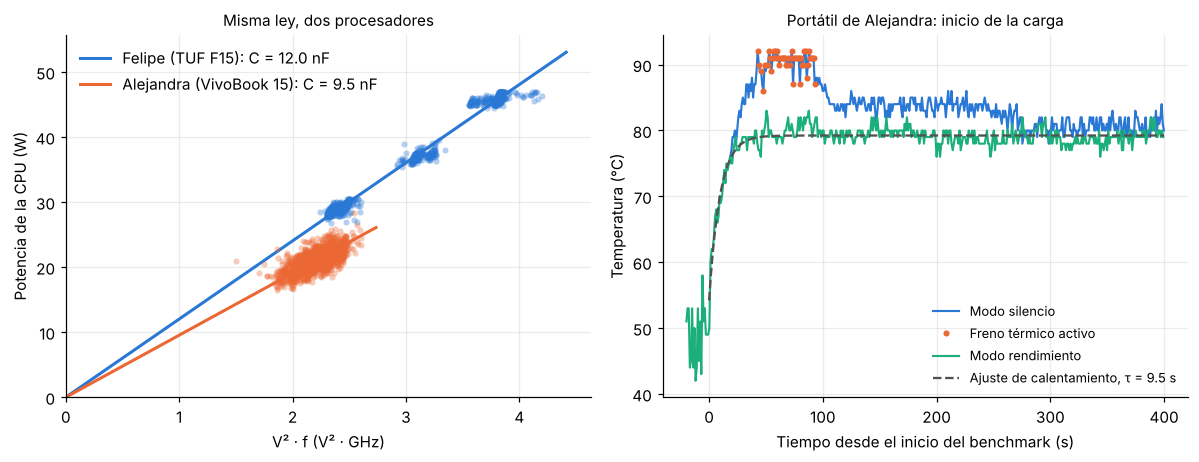

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.3))

# Izquierda: P contra V²f para los dos procesadores
for nombre, grupo, color in [("Felipe (TUF F15)", [resultados[m] for m in MODOS], AZUL),
                             ("Alejandra (VivoBook 15)", list(resultados_ale.values()), NARANJA)]:
    x = np.concatenate([g["muestras"][1]**2 * g["muestras"][2] * 1e6 for g in grupo])
    P_g = np.concatenate([g["muestras"][0] for g in grupo])
    C_g = np.sum(x * P_g) / np.sum(x**2)
    ax1.plot(x / 1e9, P_g, "o", color=color, ms=4, alpha=0.35, mec="none")
    x_l = np.linspace(0, x.max() * 1.05, 50)
    ax1.plot(x_l / 1e9, C_g * x_l, color=color, lw=2, label=f"{nombre}: C = {C_g * 1e9:.1f} nF")
ax1.set_xlim(left=0); ax1.set_ylim(bottom=0)
ax1.set_xlabel("V² · f (V² · GHz)")
ax1.set_ylabel("Potencia de la CPU (W)")
ax1.set_title("Misma ley, dos procesadores", fontsize=10)
ax1.legend(loc="upper left")

# Derecha: primeros 400 s de carga en los dos modos de Alejandra
def calentamiento(t, T_inf, A, tau):
    return T_inf - A * np.exp(-t / tau)

for modo, color in [("silencio", AZUL), ("rendimiento", AGUA)]:
    h = resultados_ale[modo]["hw"]
    m = (h["t"] >= -20) & (h["t"] <= 400)
    ax2.plot(h["t"][m], h["T"][m], color=color, lw=1.4, label=f"Modo {modo}")
    if modo == "silencio":
        frena = m & (h["freno_termico"] == 1)
        ax2.plot(h["t"][frena], h["T"][frena], "o", color=NARANJA, ms=4, mec="none",
                 label="Freno térmico activo")
        print(f"Silencio: freno térmico activo entre t = {h['t'][frena].min():.0f} y {h['t'][frena].max():.0f} s, "
              f"T máx = {h['T'][m].max():.0f} °C")
    else:
        mc = (h["t"] >= 0) & (h["t"] <= 400)
        (T_inf_c, A_c, tau_cal), cov_c = curve_fit(calentamiento, h["t"][mc], h["T"][mc], p0=[80, 30, 20])
        t_f = np.linspace(0, 400, 300)
        ax2.plot(t_f, calentamiento(t_f, T_inf_c, A_c, tau_cal), "--", color=GRIS, lw=1.5,
                 label=f"Ajuste de calentamiento, τ = {tau_cal:.1f} s")
        print(f"Rendimiento: τ de calentamiento = {tau_cal:.1f} ± {np.sqrt(cov_c[2, 2]):.1f} s | "
              f"τ de enfriamiento = {resultados_ale['rendimiento']['tau']:.0f} s")
ax2.set_xlabel("Tiempo desde el inicio del benchmark (s)")
ax2.set_ylabel("Temperatura (°C)")
ax2.set_title("Portátil de Alejandra: inicio de la carga", fontsize=10)
ax2.legend(loc="lower right", fontsize=8.5)
fig.tight_layout()
fig.savefig("figuras/segundo_equipo.png", dpi=200)
plt.show()

**Interpretación.**

- **Vimos el freno térmico en un chip real.** En modo Silencio el ventilador va más despacio y la temperatura sube hasta 92 °C; entre $t \approx 43$ s y $t \approx 93$ s HWiNFO marca "desaceleración térmica: Sí". Es el freno de la sección 9, pero aquí fue leve y corto: la frecuencia promedio bajó menos de un 1 % y la velocidad no cambió de forma medible. Luego el ventilador acelera y la temperatura se queda entre 77 y 86 °C.
- **Calentar y enfriar no tardan lo mismo.** El modelo de un solo cuerpo predice el mismo $\tau$ al calentar y al enfriar. Pero el ajuste da unos **10 s al calentar** y **33 s al enfriar**. La explicación es que hay al menos dos cuerpos: el chip de silicio, que tiene muy poca masa y se calienta en segundos (es la misma caída rápida que vimos en los primeros 2 s del enfriamiento de Felipe), y el disipador, que es más lento. Además, el ventilador cambia de velocidad durante la prueba, y con él $R_{th}$. Esta es la principal limitación de nuestro modelo térmico, y la discutimos en la sección 14.

### 8.8 ¿El modelo reproduce lo que medimos?

Hasta aquí usamos la medición para sacar parámetros. Ahora hacemos la prueba al revés: le damos al modelo de un solo cuerpo la **potencia medida** $P(t)$ de HWiNFO, segundo a segundo, lo integramos con nuestro `euler` y comparamos la temperatura que predice con la que midió el sensor.

Los parámetros salen de las propias mediciones:

- $R_{th}$: de comparar la carga estable con el reposo (sección 8.5).
- $C_{th} = \tau / R_{th}$, con $\tau$ de la curva de enfriamiento.
- $T_{amb,ef} = T_{reposo} - R_{th}\,P_{reposo}$. Es la temperatura "ambiente" que ve el chip, es decir, la del aire dentro del portátil, no la del cuarto.

Hacemos dos pruebas:

1. **Portátil de Felipe, modo Silencio,** con los parámetros de esa misma medición. Como los parámetros salen de los mismos datos, esto no es una predicción: muestra hasta dónde llega un modelo de un solo cuerpo, sobre todo en los cambios bruscos de potencia.
2. **Portátil de Alejandra, modo Rendimiento,** pero con los parámetros de su modo **Silencio**. Esta sí es una predicción: el modelo no vio estos datos.

Prueba                                      R_th  C_th T_amb,ef | error RMS (°C): 1.er minuto  carga enfriam.  total
Felipe · Silencio                           1.22    36     41.5 |                         3.3    1.1      5.9    3.2
Alejandra · Rendimiento                     2.17    18     34.6 |                         9.4    3.1      5.0    4.3


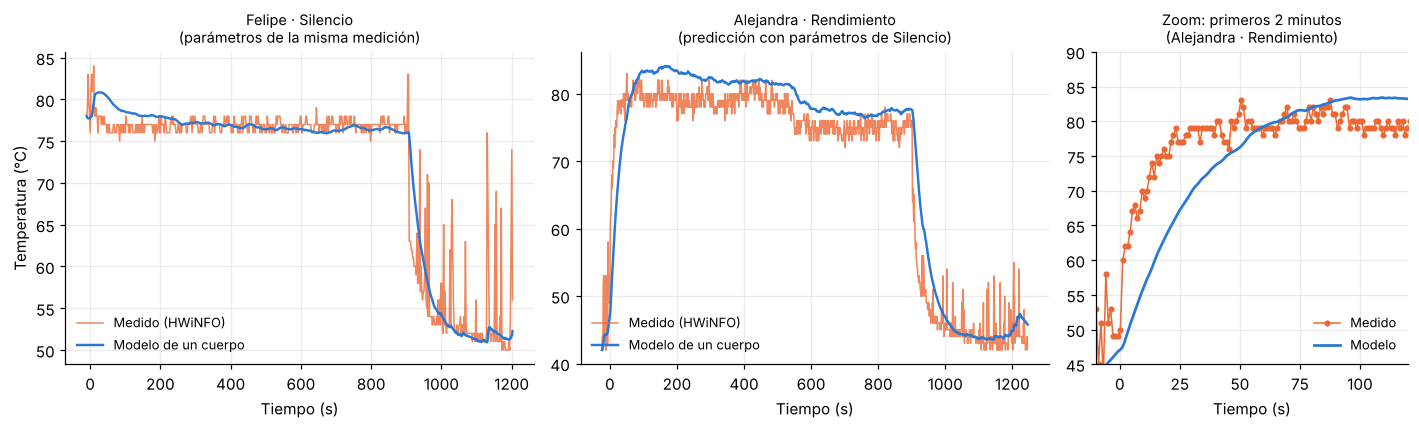

In [15]:
def parametros_medidos(x):
    h = x["hw"]
    reposo = h["t"] > h["t"].max() - 100
    R = x["R_th"]
    C = x["tau"] / R
    T_amb_ef = np.median(h["T"][reposo]) - R * np.median(h["P"][reposo])
    return R, C, T_amb_ef


def simular_medicion(x, R, C, T_amb_ef, dt=0.5):
    # Euler con la potencia MEDIDA como entrada (interpolada entre muestras)
    h = x["hw"]
    t0 = h["t"][0]
    F = lambda t, T: (np.interp(t + t0, h["t"], h["P"]) - (T - T_amb_ef) / R) / C
    t, T = euler(F, h["T"][0], dt, h["t"][-1] - t0)
    return t + t0, T


pruebas = [
    ("Felipe · Silencio\n(parámetros de la misma medición)", resultados["silencio"], resultados["silencio"]),
    ("Alejandra · Rendimiento\n(predicción con parámetros de Silencio)", resultados_ale["rendimiento"], resultados_ale["silencio"]),
]
fig, ejes = plt.subplots(1, 3, figsize=(13, 4), gridspec_kw={"width_ratios": [1.2, 1.2, 0.8]})
print(f"{'Prueba':42s}{'R_th':>6s}{'C_th':>6s}{'T_amb,ef':>9s} | error RMS (°C):{'1.er minuto':>12s}{'carga':>7s}{'enfriam.':>9s}{'total':>7s}")
for (nombre, x, x_param), ax in zip(pruebas, ejes[:2]):
    R, C, T_amb_ef = parametros_medidos(x_param)
    t_sim, T_sim = simular_medicion(x, R, C, T_amb_ef)
    h = x["hw"]
    error = np.interp(h["t"], t_sim, T_sim) - h["T"]
    tramos = [(h["t"] >= 0) & (h["t"] < 60), (h["t"] >= 60) & (h["t"] < 900), h["t"] >= 902, h["t"] > -1e9]
    rms = [np.sqrt(np.mean(error[m]**2)) for m in tramos]
    print(f"{nombre.split(chr(10))[0]:42s}{R:6.2f}{C:6.0f}{T_amb_ef:9.1f} | {'':15s}{rms[0]:12.1f}{rms[1]:7.1f}{rms[2]:9.1f}{rms[3]:7.1f}")
    ax.plot(h["t"], h["T"], color=NARANJA, lw=1, alpha=0.8, label="Medido (HWiNFO)")
    ax.plot(t_sim, T_sim, color=AZUL, lw=1.6, label="Modelo de un cuerpo")
    ax.set_title(nombre, fontsize=9.5)
    ax.set_xlabel("Tiempo (s)")
    ax.legend(loc="lower left", fontsize=8.5)
    if x is resultados_ale["rendimiento"]:
        ejes[2].plot(h["t"], h["T"], "o-", color=NARANJA, ms=3, lw=1, label="Medido")
        ejes[2].plot(t_sim, T_sim, color=AZUL, lw=1.8, label="Modelo")
ejes[0].set_ylabel("Temperatura (°C)")
ejes[2].set_xlim(-10, 120)
ejes[2].set_ylim(45, 90)
ejes[2].set_title("Zoom: primeros 2 minutos\n(Alejandra · Rendimiento)", fontsize=9.5)
ejes[2].set_xlabel("Tiempo (s)")
ejes[2].legend(loc="lower right", fontsize=8.5)
fig.tight_layout()
fig.savefig("figuras/modelo_vs_medicion.png", dpi=200)
plt.show()

**Interpretación.** Con la potencia medida como entrada, el modelo de un solo cuerpo sigue la temperatura real con un error total de unos 3 °C, y de 1 a 3 °C durante la carga estable. Es decir, la ecuación $C_{th}\,dT/dt = P - (T - T_{amb})/R_{th}$ captura bien lo esencial.

Falla en dos lugares, y los dos dicen algo físico:

- **El primer minuto.** El chip real se calienta mucho más rápido que el modelo (en el zoom, el modelo se queda 6 a 8 °C por debajo). Un solo $\tau$ no alcanza: el silicio, que tiene muy poca masa, se calienta en segundos, y el disipador tarda decenas de segundos. Es la misma diferencia entre $\tau$ de calentamiento y de enfriamiento de la sección 8.7, y la causa de que el error sea mayor en el enfriamiento.
- **El ventilador.** En la predicción para Alejandra el modelo queda unos 3 °C más caliente durante la carga, porque usamos el $R_{th}$ del modo Silencio y en Rendimiento el ventilador gira más rápido. $R_{th}$ no es una constante del portátil: depende del aire que mueve el ventilador.

Para mejorar el modelo harían falta dos cuerpos (chip y disipador, cada uno con su capacidad térmica) y un $R_{th}$ que dependa de la velocidad del ventilador. Para la pregunta del proyecto no cambia mucho: los ataques que nos interesan duran horas o años, y ahí lo que cuenta es el equilibrio, que el modelo sí reproduce.

---
## 9. Frenado: cómo se protege el chip

En la medición (sección 8) el procesador nunca dejó que su temperatura subiera sin control: cada modo le fija un **tope de potencia**, y además el chip tiene un **límite térmico** por si eso no alcanza. Una GPU tiene los mismos dos frenos. En esta sección los agregamos al modelo.

### 9.1 Potencia en función de la frecuencia

Usamos la frecuencia relativa $\varphi = f/f_{máx}$, de modo que $\varphi = 1$ es la velocidad máxima. La velocidad de intentos es $r = r_{máx}\,\varphi$ y la potencia es $P = C V^2 f$. Cuando un chip baja la frecuencia también baja el voltaje (lo vimos en la sección 8.5). Ajustamos una recta a los tres puntos $(f, V)$ que medimos y la normalizamos:

$$
\frac{V}{V_{máx}} = a + (1-a)\,\varphi
\qquad\Longrightarrow\qquad
P(\varphi) = P_{máx}\;\varphi\,\big(a + (1-a)\,\varphi\big)^2 .
$$

Como $r \propto \varphi$, la **energía por intento** es $P/r \propto \big(a + (1-a)\varphi\big)^2$: ir más despacio sale más barato por intento, igual que el modo Silencio en nuestro portátil.

**Suposición:** la GPU escala su voltaje igual que nuestro procesador. Solo lo medimos entre $\varphi \approx 0.8$ y $\varphi = 1$, que es justamente el rango en el que trabaja el frenado.

Recta medida: V = 0.320 V + 0.199 V/GHz · f
a = V(0) / V(f_máx) = 0.311


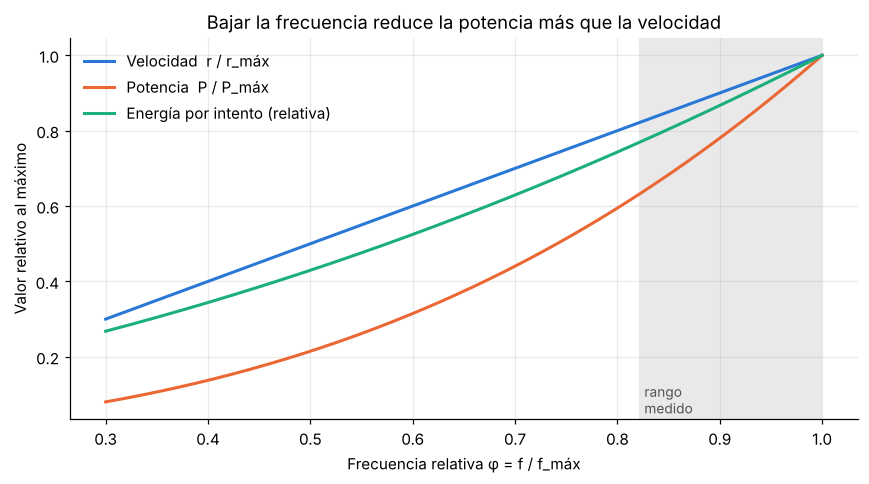

Con φ = 0.8: velocidad 80 %, potencia 59 %


In [16]:
f_modos = np.array([resultados[m]["f"] for m in MODOS])   # MHz
V_modos = np.array([resultados[m]["V"] for m in MODOS])   # V
pendiente_V, corte_V = np.polyfit(f_modos, V_modos, 1)
A_DVFS = corte_V / (pendiente_V * f_modos.max() + corte_V)
print(f"Recta medida: V = {corte_V:.3f} V + {pendiente_V * 1000:.3f} V/GHz · f")
print(f"a = V(0) / V(f_máx) = {A_DVFS:.3f}")


def potencia(phi):
    # Potencia eléctrica (W) con frecuencia relativa phi, incluyendo la bajada de voltaje
    return P_MAX * phi * (A_DVFS + (1 - A_DVFS) * phi)**2


def biseccion(g, izq, der, tol=1e-9):
    # Raíz de g en [izq, der] por bisección; g(izq) y g(der) deben tener signos opuestos
    g_izq = g(izq)
    while der - izq > tol:
        medio = (izq + der) / 2
        g_medio = g(medio)
        if (g_medio > 0) == (g_izq > 0):
            izq, g_izq = medio, g_medio
        else:
            der = medio
    return (izq + der) / 2


phi_graf = np.linspace(0.3, 1, 200)
fig, ax = plt.subplots()
ax.plot(phi_graf, phi_graf, color=AZUL, label="Velocidad  r / r_máx")
ax.plot(phi_graf, potencia(phi_graf) / P_MAX, color=NARANJA, label="Potencia  P / P_máx")
ax.plot(phi_graf, (A_DVFS + (1 - A_DVFS) * phi_graf)**2, color=AGUA, label="Energía por intento (relativa)")
ax.axvspan(f_modos.min() / f_modos.max(), 1, color=GRIS, alpha=0.12, lw=0)
ax.text(f_modos.min() / f_modos.max() + 0.005, 0.05, "rango\nmedido", color=GRIS, fontsize=9)
ax.set_xlabel("Frecuencia relativa φ = f / f_máx")
ax.set_ylabel("Valor relativo al máximo")
ax.set_title("Bajar la frecuencia reduce la potencia más que la velocidad")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig("figuras/potencia_vs_frecuencia.png", dpi=200)
plt.show()
print(f"Con φ = 0.8: velocidad 80 %, potencia {100 * potencia(0.8) / P_MAX:.0f} %")

### 9.2 Los dos frenos

- **Tope de potencia.** El chip no puede pasar de $P_{tope}$, así que $\varphi \le \varphi_P$, donde $P(\varphi_P) = P_{tope}$. Esa ecuación no tiene despeje sencillo, así que la resolvemos por bisección. Es lo que hacen los modos del portátil.
- **Límite térmico.** Probamos dos reglas:
  - *Proporcional:* por cada grado por encima de $T_{lím}$ la frecuencia baja una fracción $K$: $\;\varphi_T = 1 - K\,(T - T_{lím})$, limitada entre $\varphi_{mín}$ y 1.
  - *Encendido/apagado:* si $T > T_{lím}$, $\varphi_T = \varphi_{mín}$; si no, $\varphi_T = 1$.

El chip obedece al freno más estricto: $\varphi = \min(\varphi_P,\ \varphi_T(T))$. Así, la ecuación del chip sigue siendo una sola,

$$
C_{th}\frac{dT}{dt} = P\big(\varphi(T)\big) - \frac{T - T_{amb}}{R_{th}},
$$

pero ahora es **no lineal**, porque $\varphi$ depende de $T$. Ya no tiene solución analítica sencilla, y la resolvemos con el mismo `euler` de la sección 4.

In [17]:
PHI_MIN = 0.5    # frecuencia relativa mínima a la que puede bajar el chip
K_FRENO = 0.10   # 1/°C: la frecuencia baja 10 % por cada grado sobre T_LIM


def phi_por_tope(P_tope):
    # Frecuencia relativa máxima permitida por el tope de potencia
    if P_tope >= P_MAX:
        return 1.0
    return biseccion(lambda p: potencia(p) - P_tope, 0.0, 1.0)


def regla_frenado(P_tope=P_MAX, control="proporcional"):
    # Devuelve la función phi(T) con los dos frenos
    phi_P = phi_por_tope(P_tope)

    def phi(T):
        if control == "proporcional":
            phi_T = min(1.0, max(PHI_MIN, 1 - K_FRENO * (T - T_LIM)))
        elif control == "on/off":
            phi_T = PHI_MIN if T > T_LIM else 1.0
        else:                       # sin freno térmico
            phi_T = 1.0
        return min(phi_P, phi_T)

    return phi


def simular(R_th, P_tope=P_MAX, control="proporcional", dt=0.5, t_final=600):
    phi = regla_frenado(P_tope, control)
    F = lambda t, T: (potencia(phi(T)) - (T - T_AMB) / R_th) / C_TH
    t, T = euler(F, T_AMB, dt, t_final)
    return t, T, np.array([phi(x) for x in T])


ESCENARIOS = {
    "A: disipador bueno": dict(R_th=R_BUENO, P_tope=P_MAX),
    "B: disipador malo": dict(R_th=R_MALO, P_tope=P_MAX),
    "C: bueno con tope de 300 W": dict(R_th=R_BUENO, P_tope=300.0),
}
COLOR_ESC = dict(zip(ESCENARIOS, [AZUL, NARANJA, AGUA]))

### 9.3 Tres escenarios

- **A:** disipador bueno, sin tope de potencia.
- **B:** disipador malo (polvo, pasta térmica seca), sin tope de potencia.
- **C:** disipador bueno con un tope de 300 W, como un "modo silencio" de la GPU.

A: disipador bueno           al final: T =  70.0 °C | φ = 1.000 | P =   450 W
B: disipador malo            al final: T =  84.2 °C | φ = 0.875 | P =   329 W
C: bueno con tope de 300 W   al final: T =  55.0 °C | φ = 0.841 | P =   300 W


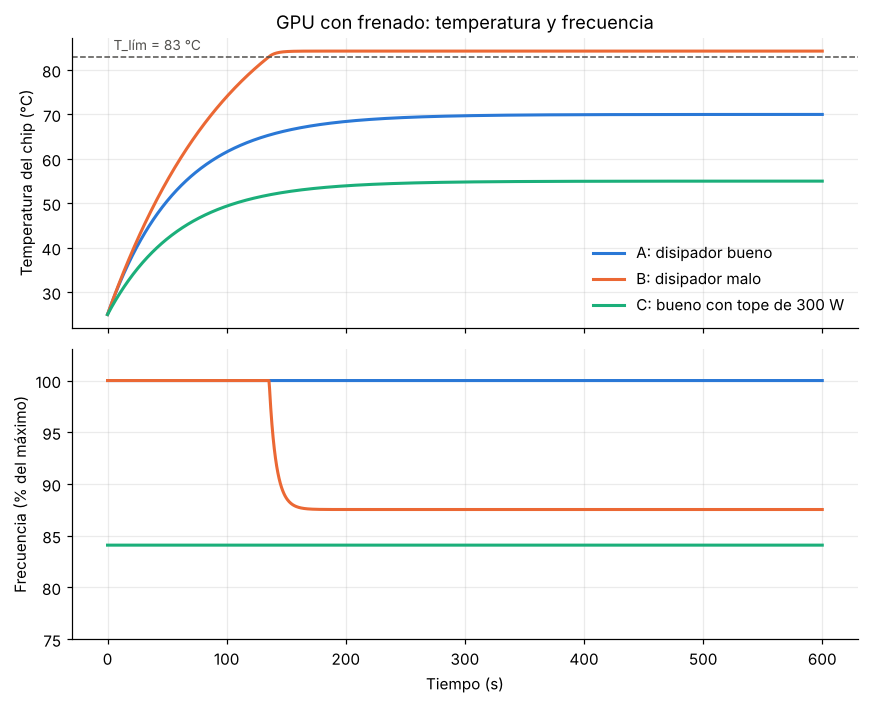

In [18]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6.5), sharex=True)
for nombre, esc in ESCENARIOS.items():
    t, T, phi = simular(**esc, dt=0.5, t_final=600)
    ax1.plot(t, T, color=COLOR_ESC[nombre], label=nombre)
    ax2.plot(t, 100 * phi, color=COLOR_ESC[nombre], label=nombre)
    print(f"{nombre:28s} al final: T = {T[-1]:5.1f} °C | φ = {phi[-1]:.3f} | P = {potencia(phi[-1]):5.0f} W")
ax1.axhline(T_LIM, color=GRIS, ls="--", lw=1)
ax1.text(5, T_LIM + 1.5, f"T_lím = {T_LIM:g} °C", color=GRIS, fontsize=9)
ax1.set_ylabel("Temperatura del chip (°C)")
ax1.set_title("GPU con frenado: temperatura y frecuencia")
ax1.legend(loc="lower right")
ax2.set_ylabel("Frecuencia (% del máximo)")
ax2.set_ylim(75, 103)
ax2.set_xlabel("Tiempo (s)")
fig.tight_layout()
fig.savefig("figuras/frenado_escenarios.png", dpi=200)
plt.show()

**Interpretación.**

- **A:** se estabiliza en 70 °C sin tocar el límite, así que trabaja al 100 % todo el tiempo.
- **B:** a los 2 minutos llega a 83 °C y el freno empieza a actuar. La temperatura se queda un poco por encima del límite y la frecuencia se estabiliza en un 88 %. El freno no apaga el calentamiento: busca la frecuencia exacta en la que el calor que entra iguala al que el disipador logra sacar.
- **C:** el tope de potencia baja la frecuencia desde el primer segundo (al 84 %). El chip queda frío (55 °C) porque nunca le llega a la temperatura límite: el freno es por potencia, que es lo mismo que medimos en el portátil.

### 9.4 Comprobación: ¿la simulación llega al equilibrio?

En el equilibrio $dT/dt = 0$, así que la temperatura final debe cumplir

$$
G(T) = P\big(\varphi(T)\big) - \frac{T - T_{amb}}{R_{th}} = 0 .
$$

Resolvemos esa ecuación por bisección y la comparamos con el final de la simulación.

**Ojo: esto no es una validación independiente del modelo.** Si Euler deja de cambiar, es porque $T_{k+1} = T_k + \Delta t\,F(T_k)$ con $T_{k+1} = T_k$, es decir $F(T_k) = 0$, que es la misma ecuación $G(T) = 0$. Las dos cosas tienen que coincidir por construcción. Lo que sí comprueba es que la simulación corrió el tiempo suficiente, que no quedó oscilando y que la bisección funciona (la usamos en la sección 11.2). La validación del modelo contra la realidad está en la sección 8.8.

In [19]:
print(f"{'Escenario':28s}{'T simulada':>12s}{'T bisección':>13s}{'diferencia':>12s}")
for nombre, esc in ESCENARIOS.items():
    phi = regla_frenado(esc["P_tope"])
    G = lambda T: potencia(phi(T)) - (T - T_AMB) / esc["R_th"]
    T_eq = biseccion(G, T_AMB, 200.0)
    _, T_sim, _ = simular(**esc, dt=0.5, t_final=1500)
    print(f"{nombre:28s}{T_sim[-1]:12.3f}{T_eq:13.3f}{abs(T_sim[-1] - T_eq):12.1e}")

Escenario                     T simulada  T bisección  diferencia
A: disipador bueno                70.000       70.000     8.6e-10
B: disipador malo                 84.246       84.246     2.1e-10
C: bueno con tope de 300 W        55.000       55.000     4.9e-10


**Interpretación.** Coinciden con una diferencia de menos de una milmillonésima de grado: en 1500 s la simulación ya llegó al equilibrio en los tres escenarios.

### 9.5 El frenado vuelve el sistema más rápido: cuidado con $\Delta t$

Con el freno proporcional, si la temperatura sube un grado sobre el equilibrio la frecuencia baja $K$, y la potencia baja $K\,P'(\varphi)$. Linealizando alrededor del equilibrio, la distancia $u = T - T_{eq}$ cumple

$$
C_{th}\frac{du}{dt} = -\left(\frac{1}{R_{th}} + K\,P'(\varphi_{eq})\right)u
\qquad\Longrightarrow\qquad
\tau_{ef} = \frac{C_{th}}{1/R_{th} + K\,P'(\varphi_{eq})} .
$$

El freno añade una "salida de calor" extra, así que el sistema reacciona mucho más rápido que $\tau = R_{th}C_{th}$. Por la sección 7, Euler oscila si $\Delta t > \tau_{ef}$ y se vuelve inestable si $\Delta t > 2\tau_{ef}$. Lo comprobamos con el escenario B y las dos reglas de freno.

τ sin freno = 108 s | τ efectivo con freno = 6.5 s
Euler oscila si Δt > 6.5 s y no converge si Δt > 12.9 s

on/off, Δt =  0.5 s: oscilación de 0.3 °C, φ promedio = 0.818
on/off, Δt =  8.0 s: oscilación de 4.5 °C, φ promedio = 0.816
proporcional:        φ en equilibrio = 0.875


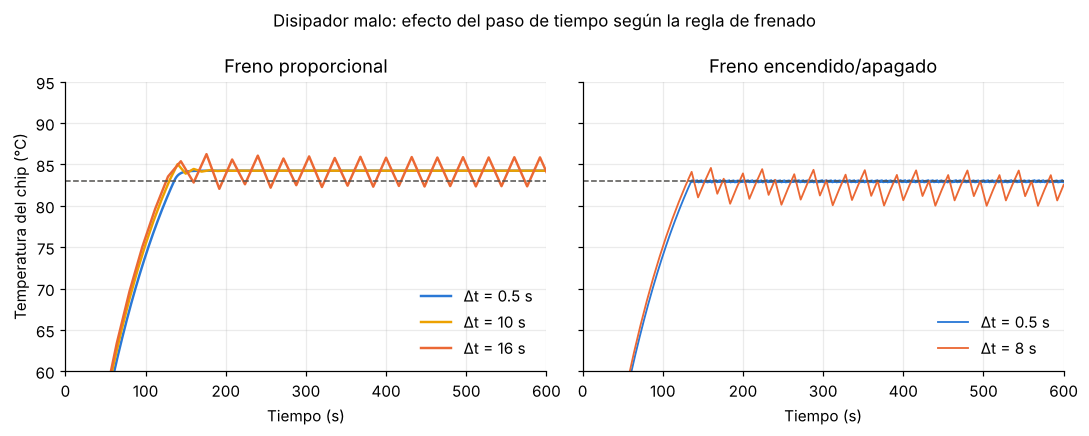

In [20]:
R = R_MALO
phi_B = regla_frenado()
T_eq_B = biseccion(lambda T: potencia(phi_B(T)) - (T - T_AMB) / R, T_AMB, 200.0)
phi_eq = phi_B(T_eq_B)
dP = (potencia(phi_eq + 1e-6) - potencia(phi_eq - 1e-6)) / 2e-6     # derivada numérica P'(φ)
tau_ef = C_TH / (1 / R + K_FRENO * dP)
print(f"τ sin freno = {R * C_TH:.0f} s | τ efectivo con freno = {tau_ef:.1f} s")
print(f"Euler oscila si Δt > {tau_ef:.1f} s y no converge si Δt > {2 * tau_ef:.1f} s\n")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for dt, color in [(0.5, AZUL), (10, AMARILLO), (16, NARANJA)]:
    t, T, _ = simular(R, control="proporcional", dt=dt, t_final=600)
    ax1.plot(t, T, "-", color=color, lw=1.6, label=f"Δt = {dt:g} s")
for dt, color in [(0.5, AZUL), (8, NARANJA)]:
    t, T, phi = simular(R, control="on/off", dt=dt, t_final=1200)
    ax2.plot(t[t <= 600], T[t <= 600], "-", color=color, lw=1.2, label=f"Δt = {dt:g} s")
    final = t > 900
    print(f"on/off, Δt = {dt:4.1f} s: oscilación de {T[final].max() - T[final].min():.1f} °C, "
          f"φ promedio = {phi[final].mean():.3f}")
_, _, phi_p = simular(R, dt=0.5, t_final=1200)
print(f"proporcional:        φ en equilibrio = {phi_p[-1]:.3f}")

for ax, titulo in [(ax1, "Freno proporcional"), (ax2, "Freno encendido/apagado")]:
    ax.axhline(T_LIM, color=GRIS, ls="--", lw=1)
    ax.set_title(titulo)
    ax.set_xlabel("Tiempo (s)")
    ax.set_xlim(0, 600)
    ax.set_ylim(60, 95)
    ax.legend(loc="lower right")
ax1.set_ylabel("Temperatura del chip (°C)")
fig.suptitle("Disipador malo: efecto del paso de tiempo según la regla de frenado", fontsize=11)
fig.tight_layout()
fig.savefig("figuras/frenado_estabilidad.png", dpi=200)
plt.show()

**Interpretación.**

- **Freno proporcional:** $\tau_{ef}$ es de unos 6.5 s, unas 16 veces menor que $\tau$. Con $\Delta t = 0.5$ s la curva es suave. Con $\Delta t = 10$ s (entre $\tau_{ef}$ y $2\tau_{ef}$) aparece una oscilación que se apaga. Con $\Delta t = 16$ s (más de $2\tau_{ef}$) la oscilación es permanente y solo la contienen los límites de $\varphi$. Ninguna de esas oscilaciones es física. Un paso de 10 s, que sin freno sería perfectamente seguro ($\tau = 108$ s), con freno ya produce oscilaciones.
- **Freno encendido/apagado:** la temperatura siempre "tiembla" alrededor de 83 °C, porque el chip alterna entre velocidad completa y media velocidad. La amplitud de ese temblor es proporcional a $\Delta t$ y por tanto es un artefacto numérico. En cambio, la frecuencia promedio (0.82) es menor que con el freno proporcional (0.88), y eso no depende de $\Delta t$: como $P(\varphi)$ es una curva cóncava hacia arriba, alternar entre dos extremos gasta más potencia que quedarse en el punto medio, y el chip tiene que ir más despacio en promedio para no calentarse. Una advertencia: con $\varphi_{mín} = 0.5$ el freno encendido/apagado trabaja fuera del rango donde medimos el voltaje ($\varphi$ entre 0.82 y 1), así que sus números exactos son menos confiables que los del freno proporcional; la conclusión cualitativa no cambia.

**Decisión:** usamos el freno proporcional, con $\Delta t \le 0.5$ s, muy por debajo de $\tau_{ef}$.

---
## 10. El ataque: tiempo y energía

### 10.1 Tres ecuaciones acopladas

Ahora unimos el chip con el ataque. Además de la temperatura, llevamos la cuenta de los intentos $n$ y de la energía eléctrica $E$:

$$
\frac{dT}{dt} = \frac{1}{C_{th}}\left[P(\varphi) - \frac{T - T_{amb}}{R_{th}}\right],
\qquad
\frac{dn}{dt} = r_{máx}\,\varphi(T),
\qquad
\frac{dE}{dt} = P(\varphi(T)),
$$

desde $n = 0$ hasta $n = 95^N$. Las tres se integran con Euler en el mismo bucle. Así, la velocidad del ataque **sale de la dinámica térmica** y no de una división fija.

**Refrigeración.** Toda la energía eléctrica termina como calor $Q = E$ en el cuarto. Un aire acondicionado lo saca con un trabajo $W = Q/\mathrm{COP}$. El máximo teórico es el de Carnot, $\mathrm{COP}_{máx} = T_{frío}/(T_{caliente} - T_{frío})$; uno real ronda $\mathrm{COP} \approx 3$, que es el que usamos.

**Ataques de miles de años.** No podemos dar $10^{13}$ pasos de Euler. Pero después de unas pocas constantes de tiempo el chip ya está en equilibrio (tras $20\tau$, lo que falta del transitorio es $e^{-20} \approx 2\times10^{-9}$). Entonces simulamos paso a paso las primeras $20\tau$ y el resto lo completamos con la velocidad de equilibrio que dio la propia simulación. En 10.2 comprobamos que eso no cambia el resultado.

**Velocidades de la RTX 4090.** Tomamos el benchmark público de hashcat 6.2.6 en una RTX 4090 a frecuencias de fábrica (Chick3nman, 2022): **NTLM**, el hash de las contraseñas de Windows, 288.5 GH/s, que redondeamos a $3\times10^{11}$ intentos/s; **bcrypt**, un hash diseñado para ser lento, 184 kH/s, que redondeamos a $2\times10^{5}$. Ese número de bcrypt es con **costo 5** (32 iteraciones), el más bajo que se usa en benchmarks. Los sitios reales usan costo 10 a 12, y cada punto de costo duplica el trabajo: con costo 12 es $2^7 = 128$ veces más lento. Por eso incluimos también ese caso.

In [21]:
ALFABETO = 95
VEL_HASH = {                                # intentos/s de una RTX 4090 a φ = 1 (hashcat 6.2.6)
    "NTLM": 3e11,
    "bcrypt costo 5": 2e5,
    "bcrypt costo 12": 2e5 / 2**7,
}
COP = 3.0                                   # aire acondicionado real
AÑO = 3.156e7                               # s
COP_carnot = (273.15 + 25) / (35 - 25)
print(f"COP de Carnot (cuarto a 25 °C, exterior a 35 °C) = {COP_carnot:.0f}; usamos COP real = {COP:g}")


def ataque(N, r_max, R_th, P_tope=P_MAX, control="proporcional", dt=0.1, n_tau=20):
    # Tiempo (s) y energía eléctrica (J) para probar las 95^N combinaciones
    total = float(ALFABETO)**N
    phi = regla_frenado(P_tope, control)
    t_sim = n_tau * R_th * C_TH
    t = n = E = 0.0
    T = T_AMB
    while t < t_sim:
        ph = phi(T)
        r, P = r_max * ph, potencia(ph)
        if n + dt * r >= total:                 # el ataque termina dentro de este paso
            fraccion = (total - n) / r
            return dict(t=t + fraccion, E=E + P * fraccion, phi=ph)
        T += dt * (P - (T - T_AMB) / R_th) / C_TH
        n += dt * r
        E += dt * P
        t += dt
    ph = phi(T)                                 # equilibrio: el resto a velocidad constante
    r, P = r_max * ph, potencia(ph)
    t_resto = (total - n) / r
    return dict(t=t + t_resto, E=E + P * t_resto, phi=ph)


def tiempo_legible(s):
    if s < 60: return f"{s:.1f} s"
    if s < 3600: return f"{s / 60:.1f} min"
    if s < 86400: return f"{s / 3600:.1f} h"
    if s < AÑO: return f"{s / 86400:.1f} días"
    if s < 1e4 * AÑO: return f"{s / AÑO:.0f} años"
    return f"{s / AÑO:.1e} años"

COP de Carnot (cuarto a 25 °C, exterior a 35 °C) = 30; usamos COP real = 3


### 10.2 Validación de la extrapolación

Una contraseña de 8 caracteres con NTLM tarda unas horas, así que sí podemos simularla completa paso a paso y compararla con la versión que extrapola después de $20\tau$.

In [22]:
for nombre, esc in ESCENARIOS.items():
    rapido = ataque(8, VEL_HASH["NTLM"], **esc, dt=0.5)
    completo = ataque(8, VEL_HASH["NTLM"], **esc, dt=0.5, n_tau=1e6)
    print(f"{nombre:28s} completo: {completo['t']:9.1f} s | extrapolado: {rapido['t']:9.1f} s | "
          f"diferencia relativa: {abs(rapido['t'] - completo['t']) / completo['t']:.1e}")

A: disipador bueno           completo:   22114.0 s | extrapolado:   22114.0 s | diferencia relativa: 0.0e+00
B: disipador malo            completo:   25242.7 s | extrapolado:   25242.7 s | diferencia relativa: 6.9e-13
C: bueno con tope de 300 W   completo:   26297.2 s | extrapolado:   26297.2 s | diferencia relativa: 4.3e-13


**Interpretación.** La diferencia es despreciable. Extrapolar con la velocidad de equilibrio da el mismo resultado que simular horas enteras, y nos deja calcular ataques de miles de años en milisegundos.

### 10.3 ¿Cuánto cuesta una contraseña de 8 caracteres?

In [23]:
print(f"{'Escenario':28s}{'Hash':>17s}{'Tiempo':>14s}{'φ':>7s}{'E eléctrica':>14s}{'+ aire acond.':>15s}{'J por intento':>15s}")
for nombre, esc in ESCENARIOS.items():
    for hash_, r_max in VEL_HASH.items():
        res = ataque(8, r_max, **esc)
        E_total = res["E"] * (1 + 1 / COP)
        print(f"{nombre:28s}{hash_:>17s}{tiempo_legible(res['t']):>14s}{res['phi']:7.3f}"
              f"{res['E'] / 3.6e6:11.3g} kWh{E_total / 3.6e6:11.3g} kWh{res['E'] / float(ALFABETO)**8:15.3g}")

Escenario                                Hash        Tiempo      φ   E eléctrica  + aire acond.  J por intento
A: disipador bueno                       NTLM         6.1 h  1.000       2.76 kWh       3.69 kWh        1.5e-09
A: disipador bueno             bcrypt costo 5     1051 años  1.000   4.15e+06 kWh   5.53e+06 kWh        0.00225
A: disipador bueno            bcrypt costo 12  1.3e+05 años  1.000   5.31e+08 kWh   7.08e+08 kWh          0.288


B: disipador malo                        NTLM         7.0 h  0.875       2.31 kWh       3.08 kWh       1.25e-09
B: disipador malo              bcrypt costo 5     1201 años  0.875   3.46e+06 kWh   4.62e+06 kWh        0.00188
B: disipador malo             bcrypt costo 12  1.5e+05 años  0.875   4.43e+08 kWh   5.91e+08 kWh          0.241
C: bueno con tope de 300 W               NTLM         7.3 h  0.841       2.19 kWh       2.92 kWh       1.19e-09


C: bueno con tope de 300 W     bcrypt costo 5     1250 años  0.841   3.29e+06 kWh   4.38e+06 kWh        0.00178
C: bueno con tope de 300 W    bcrypt costo 12  1.6e+05 años  0.841   4.21e+08 kWh   5.61e+08 kWh          0.228


**Interpretación.**

- **NTLM:** con la GPU en buen estado, 8 caracteres caen en unas **6 horas** y unos **3.7 kWh** contando el aire acondicionado: más o menos lo que gasta una nevera en unos pocos días. Una contraseña así no protege nada.
- **bcrypt:** con costo 5 el mismo ataque tarda más de mil años, y con costo 12, el que usaría un sitio bien configurado, más de cien mil años. La física del chip es la misma; lo único que cambia es que bcrypt obliga a hacer muchísimo más trabajo por intento. Por eso los sistemas serios guardan las contraseñas con hashes lentos.
- **El disipador malo (B) y el tope de potencia (C)** hacen el ataque entre un 14 % y un 19 % más lento, pero gastan **menos** energía total, porque trabajan a menor voltaje. Es lo mismo que medimos en el portátil (Silencio contra Turbo): el frenado cambia tiempo por energía.

### 10.4 ¿Cuándo importa la dinámica térmica?

Para cada duración posible del ataque calculamos la **velocidad promedio** como fracción de $r_{máx}$. Si el modelo térmico no importara, sería 1 siempre.

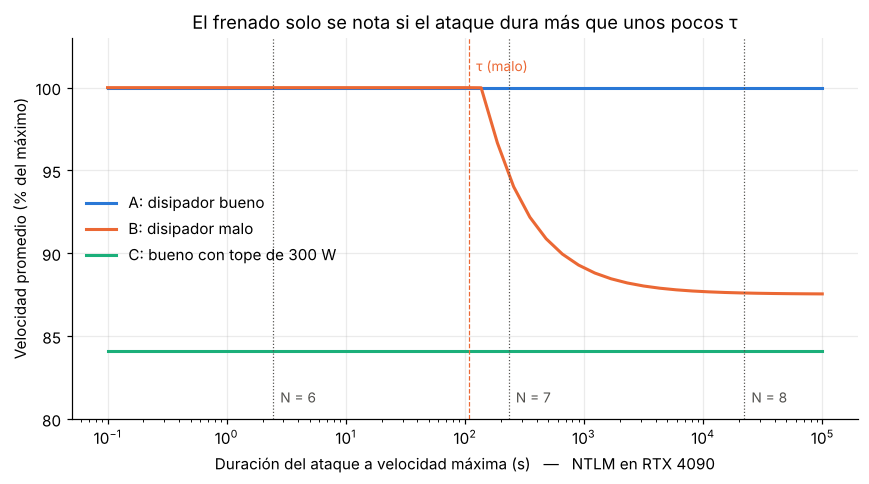

In [24]:
duraciones = np.logspace(-1, 5, 45)          # duración del ataque sin frenado, en s
fig, ax = plt.subplots()
for nombre, esc in ESCENARIOS.items():
    fraccion = []
    for d in duraciones:
        N_equiv = np.log(d * VEL_HASH["NTLM"]) / np.log(ALFABETO)   # N (no entero) con esa duración
        res = ataque(N_equiv, VEL_HASH["NTLM"], **esc, dt=0.2)
        fraccion.append(d / res["t"])
    ax.semilogx(duraciones, 100 * np.array(fraccion), color=COLOR_ESC[nombre], label=nombre)

for N in [6, 7, 8]:
    d = float(ALFABETO)**N / VEL_HASH["NTLM"]
    ax.axvline(d, color=GRIS, lw=0.8, ls=":")
    ax.text(d * 1.15, 81, f"N = {N}", color=GRIS, fontsize=9)
ax.axvline(R_MALO * C_TH, color=NARANJA, lw=0.8, ls="--")
ax.text(R_MALO * C_TH * 1.15, 101, "τ (malo)", color=NARANJA, fontsize=9)
ax.set_ylim(80, 103)
ax.set_xlabel("Duración del ataque a velocidad máxima (s)   —   NTLM en RTX 4090")
ax.set_ylabel("Velocidad promedio (% del máximo)")
ax.set_title("El frenado solo se nota si el ataque dura más que unos pocos τ")
ax.legend(loc="center left")
fig.tight_layout()
fig.savefig("figuras/velocidad_vs_duracion.png", dpi=200)
plt.show()

**Interpretación.** En el escenario B, un ataque de pocos segundos (6 caracteres) va al 100 %: el chip está frío y su capacidad térmica absorbe el calor antes de llegar al límite. Alrededor de $\tau$ la velocidad promedio empieza a caer, y para ataques largos se estabiliza en la velocidad de equilibrio. El tope de potencia (C), en cambio, actúa desde el primer segundo, sin importar la duración.

Esta gráfica es la respuesta a "¿para qué el modelo térmico, si basta dividir combinaciones entre velocidad?": la división funciona solo en los extremos, y cuál es la velocidad de equilibrio lo decide la física del disipador.

### 10.5 Tiempo y energía según la longitud de la contraseña

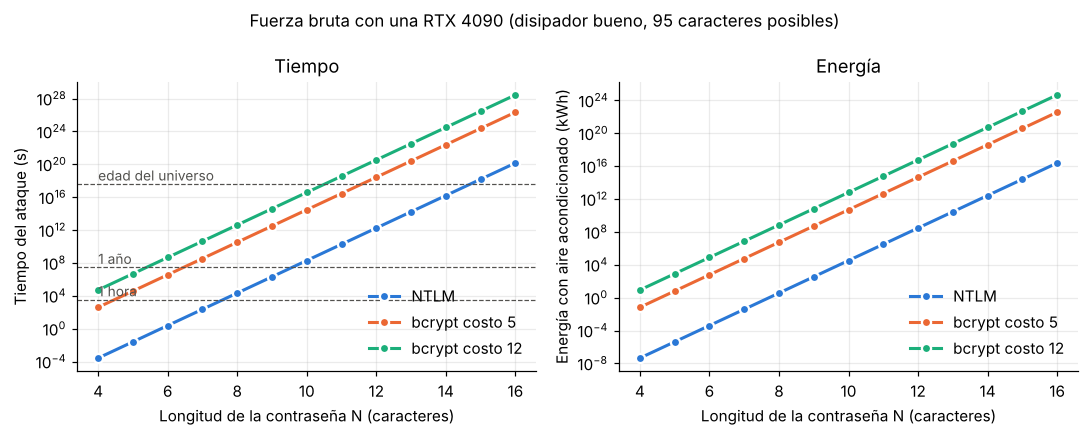

N =  8 (NTLM):            6.1 h | 3.69e+00 kWh
N = 10 (NTLM):           6 años | 3.33e+04 kWh
N = 12 (NTLM):     5.7e+04 años | 3.00e+08 kWh
N = 16 (NTLM):     4.6e+12 años | 2.45e+16 kWh


In [25]:
longitudes = np.arange(4, 17)
esc_A = ESCENARIOS["A: disipador bueno"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
for (hash_, r_max), color in zip(VEL_HASH.items(), [AZUL, NARANJA, AGUA]):
    res = [ataque(N, r_max, **esc_A) for N in longitudes]
    ax1.semilogy(longitudes, [x["t"] for x in res], "o-", color=color, ms=6, mec="white", mew=1.5, label=hash_)
    ax2.semilogy(longitudes, [x["E"] * (1 + 1 / COP) / 3.6e6 for x in res], "o-", color=color,
                 ms=6, mec="white", mew=1.5, label=hash_)

for valor, texto in [(3600, "1 hora"), (AÑO, "1 año"), (13.8e9 * AÑO, "edad del universo")]:
    ax1.axhline(valor, color=GRIS, lw=0.8, ls="--")
    ax1.text(4, valor * 2.5, texto, color=GRIS, fontsize=9)
ax1.set_ylabel("Tiempo del ataque (s)")
ax2.set_ylabel("Energía con aire acondicionado (kWh)")
for ax, titulo in [(ax1, "Tiempo"), (ax2, "Energía")]:
    ax.set_xlabel("Longitud de la contraseña N (caracteres)")
    ax.set_title(titulo)
    ax.legend(loc="lower right")
fig.suptitle("Fuerza bruta con una RTX 4090 (disipador bueno, 95 caracteres posibles)", fontsize=11)
fig.tight_layout()
fig.savefig("figuras/ataque_vs_longitud.png", dpi=200)
plt.show()

for N in [8, 10, 12, 16]:
    res = ataque(N, VEL_HASH["NTLM"], **esc_A)
    print(f"N = {N:2d} (NTLM): {tiempo_legible(res['t']):>16s} | {res['E'] * (1 + 1 / COP) / 3.6e6:.2e} kWh")

**Interpretación.** Cada carácter adicional multiplica el tiempo y la energía por 95: en escala logarítmica son líneas rectas. Con NTLM, una contraseña de 12 caracteres ya tomaría decenas de miles de años, y una de 16 supera por mucho la edad del universo. Pasar de NTLM a bcrypt con costo 5 equivale a agregar unos 3 caracteres ($95^3 \approx 10^6$), y con costo 12 unos 4. Por eso la longitud pesa más que cualquier otra regla de contraseñas.

En la sección 12 veremos si, más allá de la tecnología, la termodinámica pone un límite inferior a esa energía.

### 10.6 ¿Qué tan seguros estamos? Sensibilidad de los resultados

Varios parámetros del modelo son estimaciones. Para saber cuáles importan, cambiamos uno a la vez dentro de un rango razonable y miramos cuánto cambian el tiempo y la energía del caso de referencia: 8 caracteres, NTLM, disipador malo (escenario B, el que más depende de la física térmica).

Caso de referencia: 7.0 h, 2.31 kWh (sin aire acondicionado)

Parámetro                             tiempo (bajo / alto)     energía (bajo / alto)
Velocidad de hashcat ±20 %             +25.0 % /  -16.7 %       +25.0 % /  -16.6 %
Resistencia térmica ±20 %               -8.5 % /   +7.7 %       +12.6 % /   -9.2 %
Potencia máxima ±20 %                   -8.5 % /   +7.7 %        -9.9 % /   +8.9 %
Temperatura límite ±5 °C                +3.6 % /   -3.2 %        -4.6 % /   +4.4 %
Temperatura del cuarto ±5 °C            -3.2 % /   +3.6 %        +4.4 % /   -4.6 %
Intensidad del freno ±50 %              -0.8 % /   +0.3 %        +1.1 % /   -0.4 %
Parámetro de voltaje a ±20 %            -0.6 % /   +0.7 %        -0.7 % /   +0.8 %
Capacidad térmica ±50 %                 +0.0 % /   -0.0 %        -0.1 % /   +0.1 %


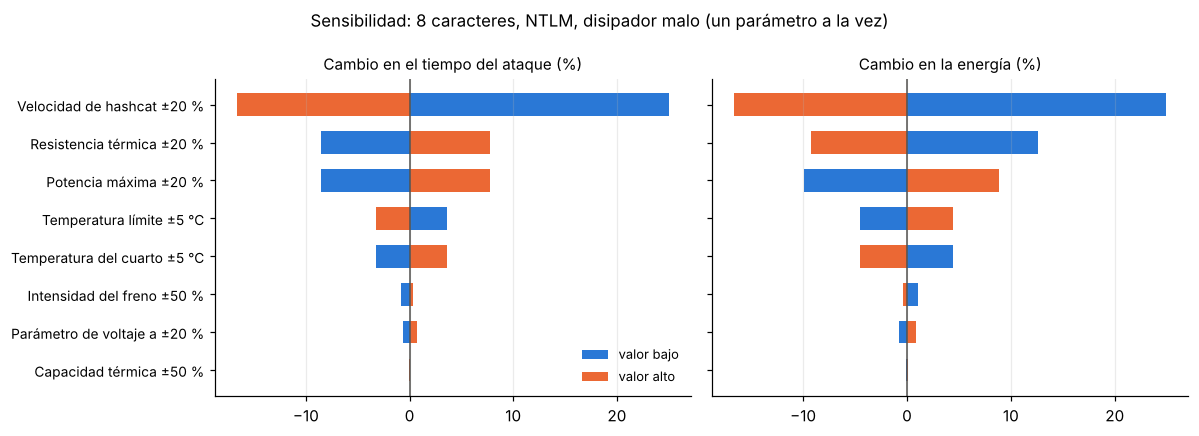

In [26]:
RANGOS = {                      # (parámetro, valor bajo, valor alto, descripción)
    "VELOCIDAD": (0.8, 1.2, "Velocidad de hashcat ±20 %"),
    "P_MAX": (0.8 * P_MAX, 1.2 * P_MAX, "Potencia máxima ±20 %"),
    "R_th": (0.8 * R_MALO, 1.2 * R_MALO, "Resistencia térmica ±20 %"),
    "T_AMB": (T_AMB - 5, T_AMB + 5, "Temperatura del cuarto ±5 °C"),
    "T_LIM": (T_LIM - 5, T_LIM + 5, "Temperatura límite ±5 °C"),
    "C_TH": (0.5 * C_TH, 1.5 * C_TH, "Capacidad térmica ±50 %"),
    "K_FRENO": (0.5 * K_FRENO, 1.5 * K_FRENO, "Intensidad del freno ±50 %"),
    "A_DVFS": (0.8 * A_DVFS, 1.2 * A_DVFS, "Parámetro de voltaje a ±20 %"),
}


def caso_referencia(**cambio):
    # Calcula el caso de referencia con UN parámetro cambiado y luego restaura el valor original
    nombre, valor = next(iter(cambio.items())) if cambio else (None, None)
    r_max, R = VEL_HASH["NTLM"], R_MALO
    original = None
    if nombre == "VELOCIDAD":
        r_max *= valor
    elif nombre == "R_th":
        R = valor
    elif nombre:
        original = globals()[nombre]
        globals()[nombre] = valor
    try:
        return ataque(8, r_max, R)
    finally:
        if original is not None:
            globals()[nombre] = original


base = caso_referencia()
filas = []
for nombre, (bajo, alto, texto) in RANGOS.items():
    r_bajo, r_alto = caso_referencia(**{nombre: bajo}), caso_referencia(**{nombre: alto})
    filas.append((texto,
                  [100 * (r["t"] / base["t"] - 1) for r in (r_bajo, r_alto)],
                  [100 * (r["E"] / base["E"] - 1) for r in (r_bajo, r_alto)]))
filas.sort(key=lambda f: max(abs(v) for v in f[1] + f[2]))

print(f"Caso de referencia: {tiempo_legible(base['t'])}, {base['E'] / 3.6e6:.2f} kWh (sin aire acondicionado)\n")
print(f"{'Parámetro':34s}{'tiempo (bajo / alto)':>24s}{'energía (bajo / alto)':>26s}")
for texto, dt_, de_ in reversed(filas):
    print(f"{texto:34s}{dt_[0]:+10.1f} % / {dt_[1]:+6.1f} %{de_[0]:+12.1f} % / {de_[1]:+6.1f} %")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
y = np.arange(len(filas))
for ax, i, titulo in [(ax1, 1, "Cambio en el tiempo del ataque (%)"), (ax2, 2, "Cambio en la energía (%)")]:
    bajos = [f[i][0] for f in filas]
    altos = [f[i][1] for f in filas]
    ax.barh(y, bajos, color=AZUL, height=0.6, label="valor bajo")
    ax.barh(y, altos, color=NARANJA, height=0.6, label="valor alto")
    ax.axvline(0, color=GRIS, lw=1)
    ax.set_title(titulo, fontsize=10)
    ax.grid(axis="y", visible=False)
ax1.set_yticks(y)
ax1.set_yticklabels([f[0] for f in filas], fontsize=9)
ax1.legend(loc="lower right", fontsize=8.5)
fig.suptitle("Sensibilidad: 8 caracteres, NTLM, disipador malo (un parámetro a la vez)", fontsize=11)
fig.tight_layout()
fig.savefig("figuras/sensibilidad.png", dpi=200)
plt.show()

**Interpretación.** El parámetro que más pesa no es térmico: es la **velocidad de hashcat** (±20 % en la velocidad mueve el tiempo entre −17 % y +25 %). Le siguen la potencia máxima y los parámetros que fijan el equilibrio ($R_{th}$, $T_{amb}$, $T_{lím}$), que cambian el resultado alrededor de un 10 % o menos. La **capacidad térmica $C_{th}$ no cambia nada**: solo afecta el primer par de minutos, y el ataque dura horas.

Esto pone el modelo térmico en su lugar. Comparado con la división simple (combinaciones / velocidad), el calor cambia el resultado en un 15 % como mucho, mientras que **un solo carácter más lo multiplica por 95**. El calor es un efecto de segundo orden. Lo importante del modelo térmico no es que cambie mucho los números, sino que explica **por qué** cambian (el equilibrio entre el calor que entra y el que sale) y que el frenado cambia tiempo por energía.

---
## 11. Costo en pesos y barridos de parámetros

### 11.1 ¿Cuánto cuesta en la factura de la luz?

Usamos la tarifa residencial de Enel Colombia para estrato 4 (sin subsidio ni contribución): **863.61 COP/kWh**, del pliego tarifario de agosto de 2026, el más reciente que encontramos publicado. La energía incluye el aire acondicionado ($\mathrm{COP} = 3$).

In [27]:
TARIFA = 863.61     # COP/kWh, Enel Colombia, estrato 4, pliego tarifario de agosto de 2026

def pesos(cop):
    if cop < 1: return "menos de $1"
    if cop < 1e6: return f"${cop:,.0f}".replace(",", ".")
    if cop < 1e12: return f"${cop / 1e6:,.1f} millones".replace(",", "X").replace(".", ",").replace("X", ".")
    return f"${cop:.1e}"

print(f"{'Hash':17s}{'N':>3s}{'Tiempo':>16s}{'Energía total':>16s}{'Costo':>22s}")
for hash_, r_max in VEL_HASH.items():
    for N in [6, 8, 10, 12]:
        res = ataque(N, r_max, **ESCENARIOS["A: disipador bueno"])
        kwh = res["E"] * (1 + 1 / COP) / 3.6e6
        print(f"{hash_:17s}{N:3d}{tiempo_legible(res['t']):>16s}{kwh:12.3g} kWh{pesos(kwh * TARIFA):>22s}")

Hash               N          Tiempo   Energía total                 Costo
NTLM               6           2.5 s    0.000408 kWh           menos de $1
NTLM               8           6.1 h        3.69 kWh                $3.183
NTLM              10          6 años    3.33e+04 kWh        $28,7 millones
NTLM              12    5.7e+04 años       3e+08 kWh   $259.255,8 millones
bcrypt costo 5     6       42.5 días         613 kWh              $529.027
bcrypt costo 5     8       1051 años    5.53e+06 kWh     $4.774,5 millones
bcrypt costo 5    10    9.5e+06 años    4.99e+10 kWh              $4.3e+13


bcrypt costo 5    12    8.6e+10 años     4.5e+14 kWh              $3.9e+17
bcrypt costo 12    6         15 años    7.84e+04 kWh        $67,7 millones
bcrypt costo 12    8    1.3e+05 años    7.08e+08 kWh   $611.132,3 millones
bcrypt costo 12   10    1.2e+09 años    6.39e+12 kWh              $5.5e+15
bcrypt costo 12   12    1.1e+13 años    5.76e+16 kWh              $5.0e+19


**Interpretación.** Romper una contraseña de 8 caracteres guardada con NTLM cuesta unos pocos miles de pesos de energía: menos que un almuerzo. Con 10 caracteres la factura sube a decenas de millones y el ataque tarda años; con 12 ya no tiene sentido hablar de costo. Con bcrypt de costo 5, incluso 8 caracteres cuestan miles de millones de pesos, y con costo 12 cuestan 128 veces más. La barrera no es técnica sino económica, y la decide la longitud.

### 11.2 Barrido: calidad del disipador y temperatura del cuarto

Para ataques largos lo que manda es el equilibrio (sección 10.4), así que podemos barrer muchos parámetros resolviendo directamente $G(T) = 0$ por bisección, sin simular. Variamos $R_{th}$ entre un disipador excelente y uno muy malo, para tres temperaturas del cuarto: 18 °C (un cuarto en Bogotá), 25 °C y 35 °C (una ciudad cálida sin aire acondicionado).

T_amb = 18 °C, disipador malo (R = 0.18 K/W): velocidad 92 %, 6.89 años, $25,6 millones
T_amb = 25 °C, disipador malo (R = 0.18 K/W): velocidad 88 %, 7.20 años, $24,1 millones
T_amb = 35 °C, disipador malo (R = 0.18 K/W): velocidad 81 %, 7.76 años, $21,9 millones


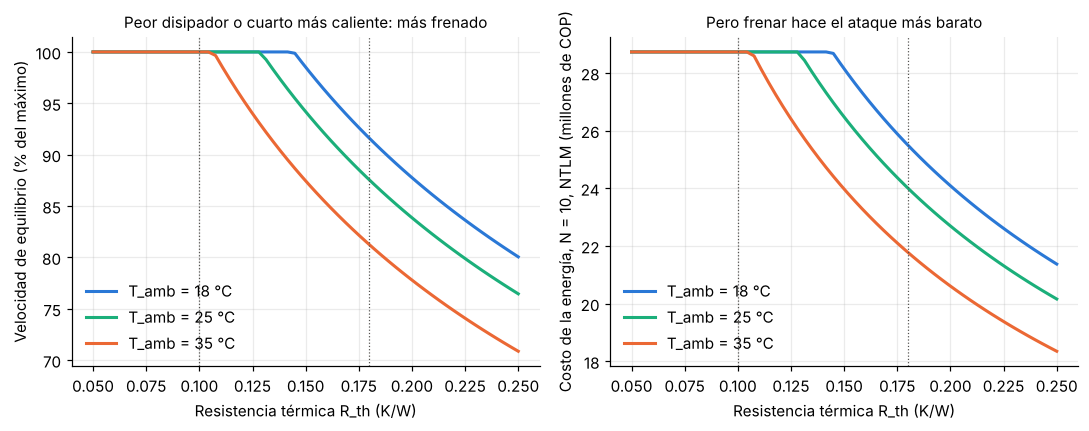

In [28]:
def equilibrio(R_th, t_amb, P_tope=P_MAX):
    # Frecuencia relativa de equilibrio con el freno proporcional
    phi = regla_frenado(P_tope)
    T_eq = biseccion(lambda T: potencia(phi(T)) - (T - t_amb) / R_th, t_amb, 250.0)
    return phi(T_eq)

R_barrido = np.linspace(0.05, 0.25, 60)
N_barrido = 10
combinaciones = float(ALFABETO)**N_barrido
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
for t_amb, color in [(18, AZUL), (25, AGUA), (35, NARANJA)]:
    phis = np.array([equilibrio(R, t_amb) for R in R_barrido])
    t_ataque = combinaciones / (VEL_HASH["NTLM"] * phis)
    costo = potencia(phis) * t_ataque * (1 + 1 / COP) / 3.6e6 * TARIFA
    ax1.plot(R_barrido, 100 * phis, color=color, label=f"T_amb = {t_amb} °C")
    ax2.plot(R_barrido, costo / 1e6, color=color, label=f"T_amb = {t_amb} °C")
    i_malo = np.argmin(abs(R_barrido - R_MALO))
    print(f"T_amb = {t_amb} °C, disipador malo (R = {R_MALO} K/W): velocidad {100 * phis[i_malo]:.0f} %, "
          f"{t_ataque[i_malo] / AÑO:.2f} años, {pesos(costo[i_malo])}")
for ax in (ax1, ax2):
    ax.legend(loc="lower left")
    ax.axvline(R_MALO, color=GRIS, lw=0.8, ls=":")
    ax.axvline(R_BUENO, color=GRIS, lw=0.8, ls=":")
    ax.set_xlabel("Resistencia térmica R_th (K/W)")
ax1.set_ylabel("Velocidad de equilibrio (% del máximo)")
ax1.set_title("Peor disipador o cuarto más caliente: más frenado", fontsize=10)
ax2.set_ylabel(f"Costo de la energía, N = {N_barrido}, NTLM (millones de COP)")
ax2.set_title("Pero frenar hace el ataque más barato", fontsize=10)
fig.tight_layout()
fig.savefig("figuras/barrido_rth_tamb.png", dpi=200)
plt.show()

**Interpretación.**

- **Izquierda.** Mientras $T_{amb} + P_{máx} R_{th}$ no pase de 83 °C, la GPU va al 100 %. A partir de ahí, cada mejora en el disipador o cada grado menos en el cuarto se convierte en velocidad. El mismo disipador malo deja la GPU mucho más rápida en un cuarto de Bogotá que en una ciudad caliente.
- **Derecha.** Hay un intercambio: cuando el chip frena, el ataque tarda más pero **cuesta menos**, porque trabaja con menos voltaje y la energía por intento baja. Con el disipador malo, el mismo ataque de 10 caracteres pasa de unos 6.9 a 7.8 años entre Bogotá y una ciudad caliente, pero su costo baja de unos 25.6 a 21.9 millones de pesos. Es el mismo resultado que medimos con los modos del portátil (sección 8.5), ahora para la GPU.

---
## 12. Límite de Landauer: el piso que pone la termodinámica

Hasta ahora todas las energías dependen de la tecnología: un chip mejor gasta menos por intento. ¿Hay un mínimo que ningún computador pueda superar?

**Principio de Landauer (1961).** Borrar un bit de información, es decir, una operación lógica irreversible, disipa al menos

$$
E_{bit} = k_B\,T\,\ln 2
$$

de calor en un ambiente a temperatura $T$. Es una consecuencia de la segunda ley: borrar un bit reduce la entropía de la memoria en $k_B \ln 2$, y esa entropía tiene que ir a parar al ambiente. Se comprobó experimentalmente en 2012 (Bérut et al., *Nature*).

**Aplicado a la fuerza bruta.** Usamos el argumento clásico de Bruce Schneier (*Applied Cryptography*, 1996): el atacante tiene que recorrer las $2^n$ claves de una llave de $n$ bits, y por cada clave descartada se borra al menos un bit de información (el resultado "esta no era"). Eso da

$$
E_{mín} \approx 2^n\,k_B\,T\,\ln 2 .
$$

Hay que leerlo como una **cota de orden de magnitud**, no como un teorema exacto. Es muy optimista para el atacante, porque supone un computador perfecto que gasta un solo $k_B T \ln 2$ por clave. Y depende de que el cómputo sea irreversible: avanzar un contador se puede hacer de forma reversible en principio, y lo que no se puede evitar es descartar cada intento fallido. Tampoco cambia mucho con la temperatura: a 3 K (el fondo cósmico de microondas) la cota es 100 veces menor, que equivale a solo unos 7 bits. Una contraseña de $N$ caracteres elegidos al azar entre 95 equivale a $n = N \log_2 95 \approx 6.57\,N$ bits.

k_B T ln2 a 300 K = 2.87e-21 J
RTX 4090 (NTLM): 1.5e-09 J por intento = 5e+11 veces el límite de Landauer
Portátil de Felipe (SHA-256 en Python): 9.1e-06 J = 3e+15 veces el límite



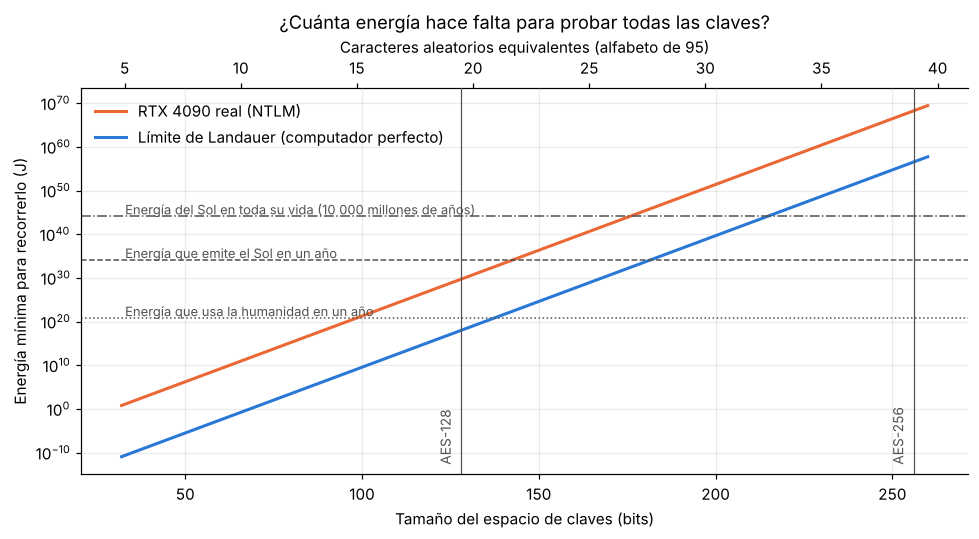

Supera...                                                           Landauer          RTX 4090
Energía que usa la humanidad en un año                        137 bits (20.9 car.)     98 bits (15.0 car.)
Energía que emite el Sol en un año                            181 bits (27.6 car.)    143 bits (21.7 car.)
Energía del Sol en toda su vida (10 000 millones de años)     215 bits (32.7 car.)    176 bits (26.8 car.)

AES-128: mínimo de Landauer = 9.8e+17 J

AES-256: mínimo de Landauer = 3.3e+56 J


In [29]:
K_B = 1.380649e-23       # J/K
T_L = 300.0              # K, temperatura ambiente
E_BIT = K_B * T_L * np.log(2)
E_GPU = P_MAX / VEL_HASH["NTLM"]                  # J por intento de la RTX 4090
E_PORTATIL = resultados["silencio"]["E_hash"]     # J por intento medido en el portátil de Felipe
L_SOL = 3.828e26         # W, luminosidad del Sol
BITS_POR_CARACTER = np.log2(ALFABETO)

REFERENCIAS = {
    "Energía que usa la humanidad en un año": 6.0e20,       # > 600 EJ en 2025 (Energy Institute)
    "Energía que emite el Sol en un año": L_SOL * AÑO,
    "Energía del Sol en toda su vida (10 000 millones de años)": L_SOL * 1e10 * AÑO,
}

print(f"k_B T ln2 a {T_L:.0f} K = {E_BIT:.2e} J")
print(f"RTX 4090 (NTLM): {E_GPU:.1e} J por intento = {E_GPU / E_BIT:.0e} veces el límite de Landauer")
print(f"Portátil de Felipe (SHA-256 en Python): {E_PORTATIL:.1e} J = {E_PORTATIL / E_BIT:.0e} veces el límite\n")

bits = np.arange(32, 261)
fig, ax = plt.subplots(figsize=(9, 5))
ax.semilogy(bits, 2.0**bits * E_GPU, color=NARANJA, label="RTX 4090 real (NTLM)")
ax.semilogy(bits, 2.0**bits * E_BIT, color=AZUL, label="Límite de Landauer (computador perfecto)")
for (texto, E), estilo in zip(REFERENCIAS.items(), [":", "--", "-."]):
    ax.axhline(E, color=GRIS, lw=1, ls=estilo)
    ax.text(33, E * 3, texto, color=GRIS, fontsize=8.5)
for n, etiqueta in [(128, "AES-128"), (256, "AES-256")]:
    ax.axvline(n, color=GRIS, lw=0.8)
    ax.text(n - 2, 1e-12, etiqueta, color=GRIS, fontsize=9, rotation=90, ha="right")
ax_sup = ax.secondary_xaxis("top", functions=(lambda b: b / BITS_POR_CARACTER, lambda N: N * BITS_POR_CARACTER))
ax_sup.set_xlabel("Caracteres aleatorios equivalentes (alfabeto de 95)")
ax.set_xlabel("Tamaño del espacio de claves (bits)")
ax.set_ylabel("Energía mínima para recorrerlo (J)")
ax.set_title("¿Cuánta energía hace falta para probar todas las claves?")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig("figuras/landauer.png", dpi=200)
plt.show()

print(f"{'Supera...':58s}{'Landauer':>18s}{'RTX 4090':>18s}")
for texto, E in REFERENCIAS.items():
    n_L, n_G = np.log2(E / E_BIT), np.log2(E / E_GPU)
    print(f"{texto:58s}{n_L:7.0f} bits ({n_L / BITS_POR_CARACTER:4.1f} car.){n_G:7.0f} bits ({n_G / BITS_POR_CARACTER:4.1f} car.)")
for n in [128, 256]:
    print(f"\nAES-{n}: mínimo de Landauer = {2.0**n * E_BIT:.1e} J")

**Interpretación.**

- **La tecnología real está lejísimos del límite.** La RTX 4090 gasta unas $5\times10^{11}$ veces más energía por intento que el mínimo de Landauer, y nuestro portátil con Python unas $3\times10^{15}$ veces más. La física deja muchísimo margen para mejorar los chips.
- **Una llave de 128 bits no está protegida por la termodinámica.** Su mínimo de Landauer es de unos $10^{18}$ J, menos del 1 % de la energía que usa la humanidad en un año. Lo que la protege es el tiempo y la tecnología real (con una RTX 4090 harían falta unos $5\times10^{29}$ J).
- **Una llave de 256 bits sí.** Su mínimo es de unos $3\times10^{56}$ J, billones de veces toda la energía que el Sol emitirá en su vida. Ningún computador irreversible, por perfecto que sea, puede recorrerla.
- **Respuesta a la pregunta del proyecto.** Para un computador perfecto, el límite está en unos **215 bits, unos 33 caracteres aleatorios**: a partir de ahí, ni la energía del Sol durante toda su vida alcanzaría. Con la tecnología actual el límite llega mucho antes: unos **15 caracteres** aleatorios ya superan toda la energía que usa la humanidad en un año.

**Límite de este argumento:** Landauer solo aplica a operaciones irreversibles. En teoría, un computador reversible podría gastar menos; hoy no existe ninguno práctico que lo haga a esta escala.

---
## 13. Demo interactiva

Escribe una contraseña y el modelo calcula su espacio de búsqueda, cuánto tardaría y cuánto costaría romperla por fuerza bruta, y muestra cómo se calentaría la GPU durante el ataque.

**No escribas una contraseña real:** el notebook guarda lo que se muestra en pantalla.

El tamaño del alfabeto se deduce de los tipos de caracteres que usa la contraseña: minúsculas (26), mayúsculas (26), dígitos (10) y símbolos (33). El tiempo mostrado es el peor caso; en promedio el atacante acierta a la mitad.

Contraseña de 12 caracteres, alfabeto de 62 símbolos: 62^12 = 2^71.5 combinaciones
Hash NTLM, A: disipador bueno
  Tiempo (peor caso): 341 años   |   en promedio: 170 años
  Energía con aire acondicionado: 1.79e+06 kWh   ->   $1.547,9 millones
  Mínimo de Landauer: 9.26e+00 J (1.5e-20 años de energía de la humanidad)


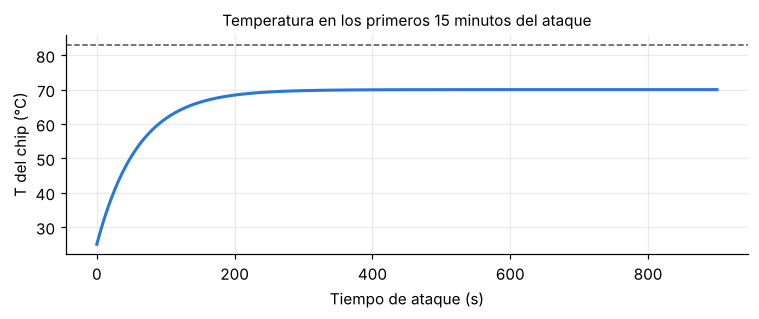

In [30]:
def tamaño_alfabeto(texto):
    n = 0
    if any(c.islower() for c in texto): n += 26
    if any(c.isupper() for c in texto): n += 26
    if any(c.isdigit() for c in texto): n += 10
    if any(not c.isalnum() for c in texto): n += 33
    return n


def demo(contraseña="Uniandes2026", hash_="NTLM", escenario="A: disipador bueno"):
    alfabeto = tamaño_alfabeto(contraseña)
    N = len(contraseña)
    if N == 0 or alfabeto == 0:
        print("Escribe una contraseña.")
        return
    bits = N * np.log2(alfabeto)
    N_equiv = bits / BITS_POR_CARACTER                 # misma cantidad de combinaciones con 95 símbolos
    esc = ESCENARIOS[escenario]
    res = ataque(N_equiv, VEL_HASH[hash_], **esc)
    kwh = res["E"] * (1 + 1 / COP) / 3.6e6

    print(f"Contraseña de {N} caracteres, alfabeto de {alfabeto} símbolos: {alfabeto}^{N} = 2^{bits:.1f} combinaciones")
    print(f"Hash {hash_}, {escenario}")
    print(f"  Tiempo (peor caso): {tiempo_legible(res['t'])}   |   en promedio: {tiempo_legible(res['t'] / 2)}")
    print(f"  Energía con aire acondicionado: {kwh:.3g} kWh   ->   {pesos(kwh * TARIFA)}")
    print(f"  Mínimo de Landauer: {2.0**bits * E_BIT:.2e} J"
          f" ({2.0**bits * E_BIT / REFERENCIAS['Energía que usa la humanidad en un año']:.1e} años de energía de la humanidad)")

    t_graf = float(np.clip(res["t"], 10, 900))
    t, T, phi = simular(**esc, dt=0.5, t_final=t_graf)
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.plot(t, T, color=COLOR_ESC[escenario])
    ax.axhline(T_LIM, color=GRIS, ls="--", lw=1)
    ax.set_xlabel("Tiempo de ataque (s)")
    ax.set_ylabel("T del chip (°C)")
    titulo = "Temperatura durante todo el ataque" if res["t"] <= 900 else "Temperatura en los primeros 15 minutos del ataque"
    ax.set_title(titulo, fontsize=10)
    fig.tight_layout()
    plt.show()


demo("Uniandes2026")

Contraseña de 30 caracteres, alfabeto de 59 símbolos: 59^30 = 2^176.5 combinaciones
Hash NTLM, A: disipador bueno
  Tiempo (peor caso): 1.4e+34 años   |   en promedio: 7.1e+33 años
  Energía con aire acondicionado: 7.42e+37 kWh   ->   $6.4e+40
  Mínimo de Landauer: 3.83e+32 J (6.4e+11 años de energía de la humanidad)


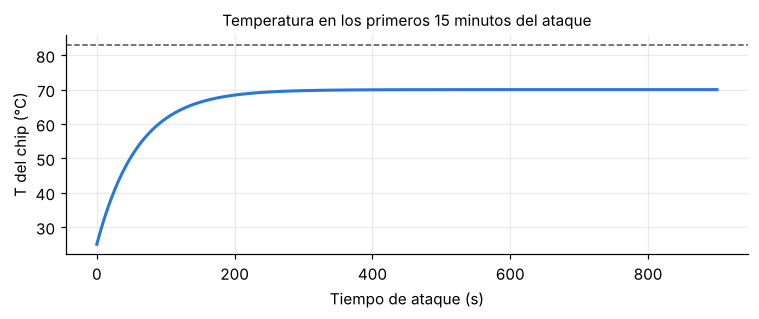

In [31]:
demo("caballo-correcto-bateria-grapa")

**Interpretación.**

- **"Uniandes2026"** parece segura porque mezcla mayúsculas, minúsculas y números, pero son solo 12 caracteres de un alfabeto de 62: por fuerza bruta pura una GPU la rompe en unos 170 años en promedio. Y como es una palabra conocida seguida de un año, un ataque de diccionario la encontraría en segundos.
- **La frase de cuatro palabras** es más fácil de recordar, y vista como 30 caracteres cualesquiera su espacio es enorme: su mínimo de Landauer equivale a cientos de miles de millones de años de toda la energía que usa la humanidad. **Pero cuidado:** si el atacante sabe que son 4 palabras de un diccionario de unas 10 000, solo hay $10^{16}$ combinaciones y la GPU las prueba en horas. El tamaño real del espacio depende de cómo se eligió la contraseña, no de cómo se ve. Por eso se recomiendan frases de más palabras, elegidas al azar.

Para probar con otras contraseñas, ejecuta la siguiente celda (requiere `ipywidgets`):

In [32]:
try:
    import ipywidgets as widgets
    widgets.interact_manual(
        demo,
        contraseña=widgets.Text(value="Uniandes2026", description="Contraseña"),
        hash_=widgets.Dropdown(options=list(VEL_HASH), value="NTLM", description="Hash"),
        escenario=widgets.Dropdown(options=list(ESCENARIOS), description="Escenario"),
    )
except ImportError:
    print("Instala ipywidgets (pip install ipywidgets) o llama demo('tu_contraseña') directamente.")

interactive(children=(Text(value='Uniandes2026', continuous_update=False, description='Contraseña'), Dropdown(…

---
## 14. Limitaciones

Las agrupamos según de dónde vienen. Para cada una decimos cuánto creemos que afecta los resultados.

**Del modelo térmico**

1. Un solo cuerpo térmico. Tratamos chip y disipador como un solo cuerpo con un único $\tau$. En la sección 8.8 vimos que eso funciona en régimen estable (error de 1 a 3 °C) pero no en el primer minuto, donde el chip real se calienta mucho más rápido (el modelo se queda 6 a 8 °C abajo). Un modelo de dos cuerpos, chip y disipador, lo describiría mejor. Para ataques largos casi no importa, porque lo que cuenta es el equilibrio.
2. $R_{th}$ constante. En la realidad depende de la velocidad del ventilador, que cambia sola durante la prueba. Al predecir el modo Rendimiento de Alejandra con el $R_{th}$ de su modo Silencio, el modelo queda unos 3 °C más caliente.
3. Ambiente constante. Suponemos que el cuarto no se calienta. En un ataque largo sí lo haría; por eso sumamos el trabajo de un aire acondicionado con COP fijo de 3, aunque en Bogotá eso es más un escenario que la realidad.

**De los parámetros**

4. No medimos una GPU. Los valores térmicos de la RTX 4090 son estimaciones, y la relación entre voltaje y frecuencia la medimos en el procesador de un portátil y la trasladamos a la GPU, solo en el rango $0.8 \le \varphi \le 1$. La sección 10.6 muestra que el resultado casi no depende de esos valores: el que más pesa es la velocidad de hashcat.
5. Velocidades de hash de terceros. Vienen de un benchmark público de hashcat en una RTX 4090. El de bcrypt es con costo 5; un sitio real usaría costo 10 a 12, entre 32 y 128 veces más lento.
6. Potencia y voltaje estimados por el propio chip. HWiNFO reporta la potencia que calcula el procesador (RAPL) y el voltaje que solicita (VID), no medidas externas. Nuestra comprobación de $P = C V^2 f$ es consistente, pero no independiente del modelo interno del chip.

**Del ataque**

7. Fuerza bruta pura. Los atacantes reales usan diccionarios y patrones ("Uniandes2026" caería en segundos), así que, para contraseñas elegidas por personas, nuestros tiempos son demasiado optimistas. Además mostramos el peor caso: en promedio el atacante acierta en la mitad del tiempo.
8. Landauer es una cota de orden de magnitud. Solo aplica a computación irreversible, y suponer un solo $k_B T \ln 2$ por clave es muy optimista para el atacante.

**De la medición**

9. Condiciones no del todo controladas: procesos de fondo de Windows, equipos que empezaron tibios, una sola corrida por modo, registro cada 2 s en las primeras mediciones, y no anotamos la temperatura del cuarto. Por eso solo en algunas mediciones el $\tau$ es confiable (los marcamos en la tabla de la sección 8.7). Nuestro benchmark en Python sirve para la física del calentamiento, no para comparar velocidades de ataque: casi toda su energía por hash es el costo de Python, no del algoritmo.

**Del método numérico**

10. Euler es de primer orden y, con el freno, el sistema tiene un $\tau_{ef}$ de unos 6.5 s. Usamos $\Delta t \le 0.5$ s y verificamos convergencia y estabilidad (secciones 6, 7 y 9.5).

## 15. Conclusiones

1. Una contraseña de 8 caracteres no protege nada si se guarda con un hash rápido. Una RTX 4090 la rompe en unas 6 horas con unos 3.7 kWh, unos pocos miles de pesos de energía. Cada carácter adicional multiplica tiempo y energía por 95: con 12 caracteres se pasa a decenas de miles de años. Guardarla con bcrypt equivale a agregar unos 3 caracteres con costo 5, y unos 4 con costo 12.

2. El calor importa, pero menos de lo que esperábamos. El balance de energía $C_{th}\,dT/dt = P - (T - T_{amb})/R_{th}$ con el frenado fija una velocidad de equilibrio: con un disipador malo la GPU trabaja al 88 %, y el ataque tarda un 14 % más. Es un efecto de segundo orden: la incertidumbre en la velocidad de hashcat pesa más, y un carácter más pesa muchísimo más. Lo que sí deja claro el modelo es el mecanismo: frenar hace el ataque más lento pero más barato, porque el chip baja también el voltaje.

3. Nuestras mediciones respaldan las partes del modelo. En dos procesadores distintos, la potencia es consistente con $P = C V^2 f$ ($C \approx 12$ nF y $9.5$ nF, con la recta pasando por el origen sin forzarla). El modo Turbo es un 22 % más rápido que el Silencio pero gasta un 30 % más de energía por intento. Vimos los dos frenos reales: por potencia en un portátil y térmico en el otro. Con la potencia medida como entrada, el modelo reproduce la temperatura con unos 3 °C de error, y donde falla (el primer minuto, el ventilador) nos dice qué le falta.

4. La termodinámica pone un piso. Según la cota de Landauer, recorrer un espacio de unos 215 bits (unos 33 caracteres aleatorios) con un computador irreversible requeriría más energía que la que el Sol emitirá en toda su vida. Una llave de 256 bits queda fuera del alcance de cualquier computador de ese tipo; una de 128 bits la protegen el tiempo y la tecnología, no la termodinámica.

5. Recomendación práctica: contraseñas largas, elegidas al azar (por ejemplo, frases de varias palabras al azar), y sistemas que las guarden con hashes lentos. La longitud gana a la complejidad.

## 16. Declaración de uso de IA

> **Borrador: el equipo debe revisarlo y completarlo con lo que realmente hizo cada integrante.**

Usamos **Claude (Anthropic)** como asistente durante el proyecto para:

- Proponer la estructura del notebook y el plan de trabajo por fases.
- Escribir y depurar el código: el integrador de Euler, el modelo de frenado, la simulación del ataque, el análisis de los datos de HWiNFO, las gráficas, la demo interactiva y el script `medicion/benchmark.py`.
- Redactar borradores de las explicaciones e interpretaciones del notebook.
- Buscar la tarifa de energía de Enel y la cifra de consumo mundial de energía.

También usamos **GitHub Copilot** para resolver un conflicto de Git.

Las mediciones de la sección 8 las hicimos nosotros en nuestros propios computadores. Revisamos el modelo físico, las ecuaciones, los resultados y el texto, y verificamos que el notebook se ejecuta de principio a fin.

*[Completar: qué revisó, modificó o escribió cada integrante.]*

**Fuentes de datos externos:** velocidades de hash de benchmarks públicos de hashcat para la RTX 4090; potencia máxima de la RTX 4090 del fabricante; tarifa de Enel Colombia (pliego tarifario de agosto de 2026); consumo mundial de energía del *Statistical Review of World Energy 2026* del Energy Institute; Landauer (1961) y Bérut et al. (2012).